In [1]:
!pip install scapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 41.0 MB/s eta 0:00:00a 0:00:01


In [2]:
import os
import pandas as pd
import numpy as np
from scapy.all import *
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.manifold import TSNE
from pandas.plotting import autocorrelation_plot
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models

2026-06-21 05:48:44.197494: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782020924.382740      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782020924.433904      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782020924.867484      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782020924.867535      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782020924.867538      57 computation_placer.cc:177] computation placer alr

EDA

Examining data structure

In [4]:
base_path = '/kaggle/input/datasets/brenda101/farm-flow-dataset/Captures/08_2022/Arp_Spoofing'

files = sorted([f for f in os.listdir(base_path) if f.endswith('.pcap')])
print(f"Found {len(files)} pcap files in Arp_Spoofing folder.")
print("Sample file:", files[:10])

Found 224 pcap files in Arp_Spoofing folder.
Sample file: ['Arp_Spoofing_00000_20220823100914.pcap', 'Arp_Spoofing_00001_20220823100919.pcap', 'Arp_Spoofing_00002_20220823100924.pcap', 'Arp_Spoofing_00003_20220823100929.pcap', 'Arp_Spoofing_00004_20220823100934.pcap', 'Arp_Spoofing_00005_20220823100939.pcap', 'Arp_Spoofing_00006_20220823100944.pcap', 'Arp_Spoofing_00007_20220823100949.pcap', 'Arp_Spoofing_00008_20220823100954.pcap', 'Arp_Spoofing_00009_20220823100959.pcap']


In [4]:
#target_file = os.path.join(base_path, 'Arp_Spoofing_0003_020220823100929.pcap')
packets = rdpcap('/kaggle/input/datasets/brenda101/farm-flow-dataset/Captures/08_2022/Arp_Spoofing/Arp_Spoofing_00003_20220823100929.pcap')

print(f"Total packets in file: {len(packets)}")
packets.summary()

Total packets in file: 79
Ether / ARP who has 192.168.1.54 says 192.168.1.7 / Padding
Ether / ARP who has 192.168.1.82 says 192.168.1.7 / Padding
Ether / ARP who has 192.168.1.28 says 192.168.1.5
Ether / ARP who has 192.168.1.5 says 192.168.1.5
Ether / ARP who has 192.168.1.54 says 192.168.1.7 / Padding
Ether / ARP who has 192.168.1.82 says 192.168.1.7 / Padding
Ether / ARP is at 2e:87:ba:40:03:b9 says 192.168.1.5
Ether / ARP is at 5c:ba:ef:e5:02:dd says 192.168.1.1 / Padding
Ether / IP / TCP 192.168.1.5:1883 > 192.168.1.9:57180 FA
Ether / IP / TCP 192.168.1.9:57180 > 192.168.1.5:1883 RA / Padding
Ether / IP / TCP 192.168.1.12:55916 > 192.168.1.5:1883 S
Ether / IP / TCP 192.168.1.5:1883 > 192.168.1.12:55916 SA
Ether / IP / TCP 192.168.1.9:64098 > 192.168.1.5:1883 S
Ether / IP / TCP 192.168.1.5:1883 > 192.168.1.9:64098 SA
Ether / IP / TCP 192.168.1.14:61853 > 192.168.1.5:1883 S
Ether / IP / TCP 192.168.1.5:1883 > 192.168.1.14:61853 SA
Ether / IP / TCP 192.168.1.9:64098 > 192.168.1.5:188

In [5]:
arp_data = []

# Analyze the packets for ARP activity
for pkt in packets:
    if pkt.haslayer(ARP):
        arp_data.append({
            "Time": pkt.time,
            "Source MAC": pkt.src,
            "Dest MAC": pkt.dst,
            "Operation": "who-has" if pkt[ARP].op == 1 else "is-at",
            "PSRC (Sender IP)": pkt[ARP].psrc,
            "HWSRC (Sender MAC)": pkt[ARP].hwsrc,
            "PDST (Target IP)": pkt[ARP].pdst
        })

arp_df = pd.DataFrame(arp_data)
arp_df.head(20)

,Time,Source MAC,Dest MAC,Operation,PSRC (Sender IP),HWSRC (Sender MAC),PDST (Target IP)
0,1661245769.392248,58:00:e3:9b:ba:91,ff:ff:ff:ff:ff:ff,who-has,192.168.1.7,58:00:e3:9b:ba:91,192.168.1.54
1,1661245769.392404,58:00:e3:9b:ba:91,ff:ff:ff:ff:ff:ff,who-has,192.168.1.7,58:00:e3:9b:ba:91,192.168.1.82
2,1661245770.006503,2e:87:ba:40:03:b9,ff:ff:ff:ff:ff:ff,who-has,192.168.1.5,2e:87:ba:40:03:b9,192.168.1.28
3,1661245770.006703,e4:5f:01:b3:6c:1b,ff:ff:ff:ff:ff:ff,who-has,192.168.1.5,e4:5f:01:b3:6c:1b,192.168.1.5
4,1661245770.314132,58:00:e3:9b:ba:91,ff:ff:ff:ff:ff:ff,who-has,192.168.1.7,58:00:e3:9b:ba:91,192.168.1.54
5,1661245770.314297,58:00:e3:9b:ba:91,ff:ff:ff:ff:ff:ff,who-has,192.168.1.7,58:00:e3:9b:ba:91,192.168.1.82
6,1661245770.315156,2e:87:ba:40:03:b9,e4:5f:01:b3:6c:1b,is-at,192.168.1.5,2e:87:ba:40:03:b9,192.168.1.5
7,1661245770.57097,5c:ba:ef:e5:02:dd,e4:5f:01:b3:6c:1b,is-at,192.168.1.1,5c:ba:ef:e5:02:dd,192.168.1.5
8,1661245772.654621,5c:ba:ef:e5:02:dd,e4:5f:01:b3:6c:1b,is-at,192.168.1.1,5c:ba:ef:e5:02:dd,192.168.1.5
9,1661245773.078844,2e:87:ba:40:03:b9,ff:ff:ff:ff:ff:ff,who-has,192.168.1.5,2e:87:ba:40:03:b9,192.168.1.15


In [6]:
csv_path = '/kaggle/input/datasets/brenda101/farm-flow-dataset/Datasets/08_2022/Arp_Spoofing/Arp_Spoofing_combined.csv'
df_csv = pd.read_csv(csv_path)

print(df_csv.columns.tolist())

['id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_paylo

In [7]:
df_csv.head()

,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,...,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,bwd_last_window_size,traffic,is_attack
0,192.168.1.4,62314,192.168.1.5,1883,tcp,-,-,-,-,SHR,...,0.0,0.0,0.0,0.0,2075,64082,2045,64048,Arp_Spoofing,1
1,192.168.1.4,55449,192.168.1.5,1883,tcp,-,3.234945,0,0,SHR,...,0.0,0.0,0.0,0.0,2144,64240,2144,64064,Arp_Spoofing,1
2,192.168.1.4,60010,192.168.1.5,1883,tcp,-,3.456003,0,0,SHR,...,0.0,0.0,0.0,0.0,0,63784,0,63784,Arp_Spoofing,1
3,192.168.1.4,55449,192.168.1.5,1883,tcp,-,-,-,-,SHR,...,0.0,0.0,0.0,0.0,0,0,0,0,Arp_Spoofing,1
4,192.168.1.4,62314,192.168.1.5,1883,tcp,-,-,-,-,SHR,...,0.0,0.0,0.0,0.0,0,64148,0,64148,Arp_Spoofing,1


In [8]:
len(df_csv)

26

In [8]:
pcap_file = "/kaggle/input/datasets/brenda101/farm-flow-dataset/Captures/08_2022/TCP_Flood/TCP_Flood_00000_20220819182445.pcap"

packets = rdpcap(pcap_file)
print(f"Total packets in file: {len(packets)}")
for i, pkt in enumerate(packets[:20], start=1):
    print(f"{i}: {pkt.summary()}")

Total packets in file: 7440
1: Ether / IP / TCP 192.168.1.9:2927 > 192.168.1.5:0 S / Padding
2: Ether / IP / TCP 192.168.1.9:2929 > 192.168.1.5:0 S / Padding
3: Ether / IP / TCP 192.168.1.9:2996 > 192.168.1.5:0 S / Padding
4: Ether / IP / TCP 192.168.1.9:3046 > 192.168.1.5:0 S / Padding
5: Ether / IP / TCP 192.168.1.9:3102 > 192.168.1.5:0 S / Padding
6: Ether / IP / TCP 192.168.1.9:3153 > 192.168.1.5:0 S / Padding
7: Ether / IP / TCP 192.168.1.9:3216 > 192.168.1.5:0 S / Padding
8: Ether / IP / TCP 192.168.1.9:3264 > 192.168.1.5:0 S / Padding
9: Ether / IP / TCP 192.168.1.9:3313 > 192.168.1.5:0 S / Padding
10: Ether / IP / TCP 192.168.1.9:3329 > 192.168.1.5:0 S / Padding
11: Ether / IP / TCP 192.168.1.9:3454 > 192.168.1.5:0 S / Padding
12: Ether / IP / TCP 192.168.1.9:3351 > 192.168.1.5:0 S / Padding
13: Ether / IP / TCP 192.168.1.9:3400 > 192.168.1.5:0 S / Padding
14: Ether / IP / TCP 192.168.1.9:3453 > 192.168.1.5:0 S / Padding
15: Ether / IP / TCP 192.168.1.9:3485 > 192.168.1.5:0 S /

In [9]:
tcp_data = []

# Only process first 1000 packets
for pkt in packets[:1000]:
    if pkt.haslayer(TCP):
        tcp_data.append({
            "Time": pkt.time,
            "Source IP": pkt[IP].src if pkt.haslayer(IP) else None,
            "Destination IP": pkt[IP].dst if pkt.haslayer(IP) else None,
            "Source Port": pkt[TCP].sport,
            "Destination Port": pkt[TCP].dport,
            "Flags": pkt[TCP].flags
        })

tcp_df = pd.DataFrame(tcp_data)
tcp_df.head(20)

,Time,Source IP,Destination IP,Source Port,Destination Port,Flags
0,1660929885.767416,192.168.1.9,192.168.1.5,2927,0,S
1,1660929885.767524,192.168.1.9,192.168.1.5,2929,0,S
2,1660929885.767553,192.168.1.9,192.168.1.5,2996,0,S
3,1660929885.767577,192.168.1.9,192.168.1.5,3046,0,S
4,1660929885.7676,192.168.1.9,192.168.1.5,3102,0,S
5,1660929885.767625,192.168.1.9,192.168.1.5,3153,0,S
6,1660929885.768676,192.168.1.9,192.168.1.5,3216,0,S
7,1660929885.769069,192.168.1.9,192.168.1.5,3264,0,S
8,1660929885.769338,192.168.1.9,192.168.1.5,3313,0,S
9,1660929885.769434,192.168.1.9,192.168.1.5,3329,0,S


Compare with normal traffic

In [9]:
normal_path = '/kaggle/input/datasets/brenda101/farm-flow-dataset/Datasets/08_2022/Normal/Normal_combined.csv'
df_normal = pd.read_csv(normal_path)

# Combine a small sample of both for comparison
comparison_df = pd.concat([
    df_csv[df_csv['is_attack'] == 1], 
    df_normal.head(30)
])

# average Flow Duration and Packet Counts
stats = comparison_df.groupby('traffic')[['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_init_window_size']].mean()
print("Comparison of Means (Normal vs Arp_Spoofing):")
display(stats)

Comparison of Means (Normal vs Arp_Spoofing):


,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_init_window_size
traffic,,,,
Arp_Spoofing,0.299218,2.038462,1.153846,5054.884615
Normal,2.343093,9.866667,9.500000,1660.700000


In [3]:
# Load dataset which contains multiple attack types
full_df_path = '/kaggle/input/datasets/brenda101/farm-flow-dataset/Datasets/Farm-Flows.csv'
full_df = pd.read_csv(full_df_path)

print(full_df['traffic'].value_counts())

/tmp/ipykernel_57/2936157789.py:3: DtypeWarning: Columns (6,7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  full_df = pd.read_csv(full_df_path)


traffic
TCP_Flood        381765
UDP_Flood        296553
HTTP_Flood       265025
MQTT_Flood       132506
Port_Scanning    126700
ICMP_Flood        76849
Normal            27458
Arp_Spoofing       2967
BotNet_DDOS          64
Name: count, dtype: int64


In [11]:
full_df.head()

,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,...,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,bwd_last_window_size,traffic,is_attack
0,192.168.1.13,37985,192.168.1.5,1883,tcp,mqtt,0.203465,151,32,OTH,...,0.0,0.0,0.0,0.0,0,0,0,0,Normal,0
1,192.168.1.4,51235,192.168.1.5,1880,tcp,http,0.013874,181,0,S1,...,0.0,0.0,0.0,0.0,2081,64048,1961,64048,Normal,0
2,192.168.1.4,63023,192.168.1.5,1880,tcp,-,0.000520,0,0,SF,...,0.0,0.0,0.0,0.0,2081,64856,1931,64856,Normal,0
3,192.168.1.9,57223,192.168.1.5,1883,tcp,mqtt,4.107098,250,150,OTH,...,0.0,0.0,0.0,0.0,2144,64240,2144,64065,Normal,0
4,192.168.1.11,50213,192.168.1.5,1883,tcp,mqtt,4.362811,250,150,OTH,...,0.0,0.0,0.0,0.0,2081,64856,1931,64856,Normal,0


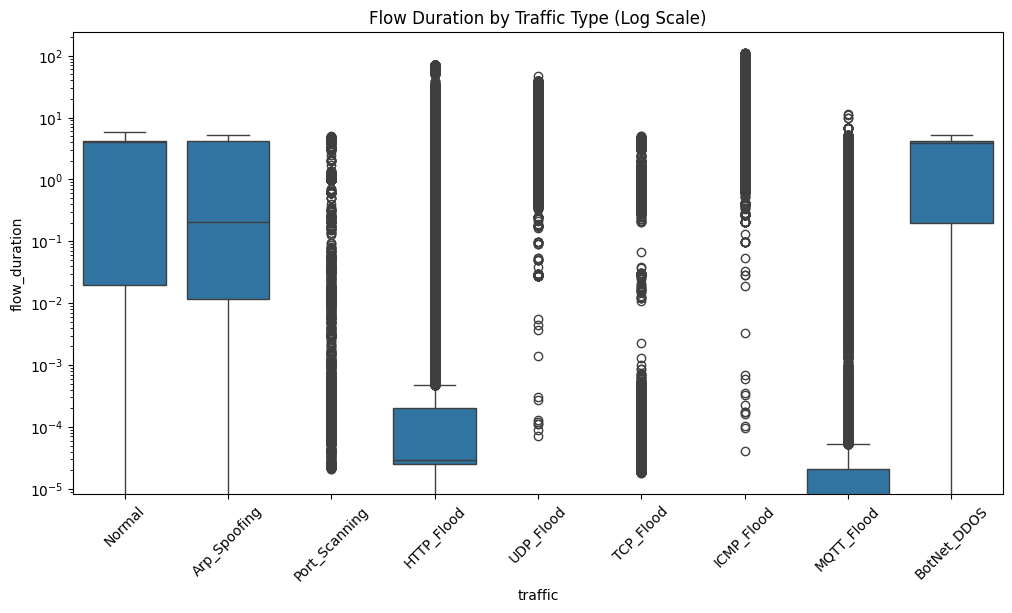

In [12]:
# Visualizing the 'Flow Duration' across different attacks
plt.figure(figsize=(12, 6))
sns.boxplot(x='traffic', y='flow_duration', data=full_df)
plt.yscale('log') # Using log scale because durations can vary alot
plt.title('Flow Duration by Traffic Type (Log Scale)')
plt.xticks(rotation=45)
plt.show()

Correlations

In [13]:
full_df['proto'].value_counts()

proto
tcp     997374
udp     312479
icmp        34
Name: count, dtype: int64

In [14]:
# full_df['proto_encoded'].value_counts()

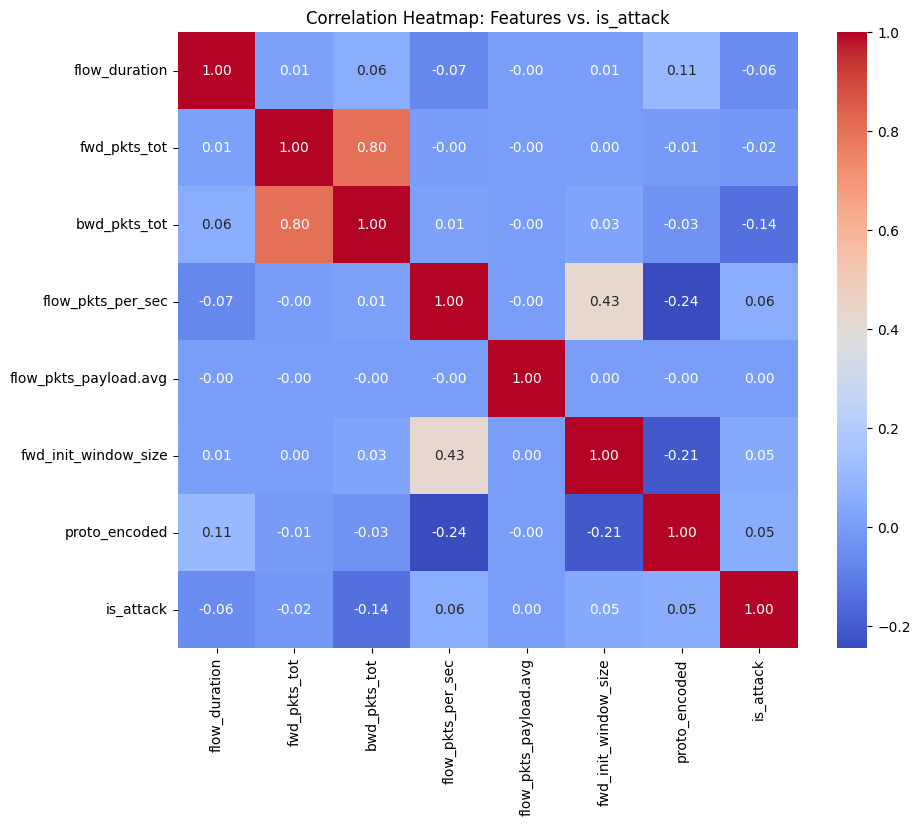

In [49]:
# Convert categorical 'proto' and 'service' to numeric so they can be correlated
le = LabelEncoder()
full_df['proto_encoded'] = le.fit_transform(full_df['proto'].astype(str))

# subset of numerical features to avoid a messy heatmap
top_features = [
    'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 
    'flow_pkts_per_sec', 'flow_pkts_payload.avg', 
    'fwd_init_window_size', 'proto_encoded', 'is_attack'
]

corr_matrix = full_df[top_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Features vs. is_attack')
plt.show()

In [16]:
corr_matrix

,flow_duration,fwd_pkts_tot,bwd_pkts_tot,flow_pkts_per_sec,flow_pkts_payload.avg,fwd_init_window_size,proto_encoded,is_attack
flow_duration,1.000000,0.010221,0.057611,-0.070387,-0.000141,0.006276,0.108905,-0.056009
fwd_pkts_tot,0.010221,1.000000,0.804198,-0.002432,-0.000006,0.000239,-0.006793,-0.018038
bwd_pkts_tot,0.057611,0.804198,1.000000,0.009471,-0.000051,0.025186,-0.032562,-0.137842
flow_pkts_per_sec,-0.070387,-0.002432,0.009471,1.000000,-0.000382,0.425879,-0.244213,0.060427
flow_pkts_payload.avg,-0.000141,-0.000006,-0.000051,-0.000382,1.000000,0.000874,-0.000489,0.000128
fwd_init_window_size,0.006276,0.000239,0.025186,0.425879,0.000874,1.000000,-0.206866,0.045261
proto_encoded,0.108905,-0.006793,-0.032562,-0.244213,-0.000489,-0.206866,1.000000,0.052666
is_attack,-0.056009,-0.018038,-0.137842,0.060427,0.000128,0.045261,0.052666,1.000000


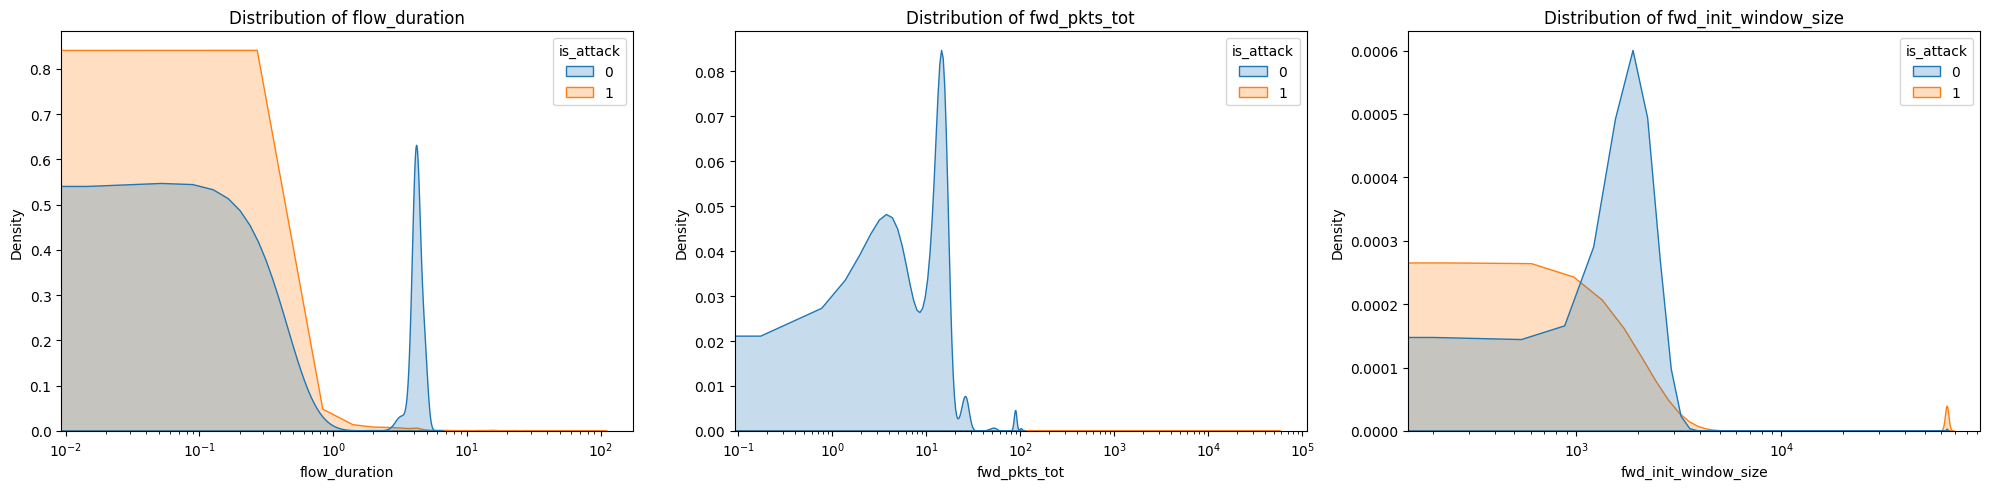

In [17]:
# picking 3 features to see how they overlap
features_to_plot = ['flow_duration', 'fwd_pkts_tot', 'fwd_init_window_size']

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, col in enumerate(features_to_plot):
    sns.kdeplot(data=full_df, x=col, hue='is_attack', fill=True, ax=axes[i], common_norm=False)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xscale('log') # Log scale for better visibility of outliers

plt.tight_layout()
plt.show()

Mutual Information (Non-Linear Feature Importance)

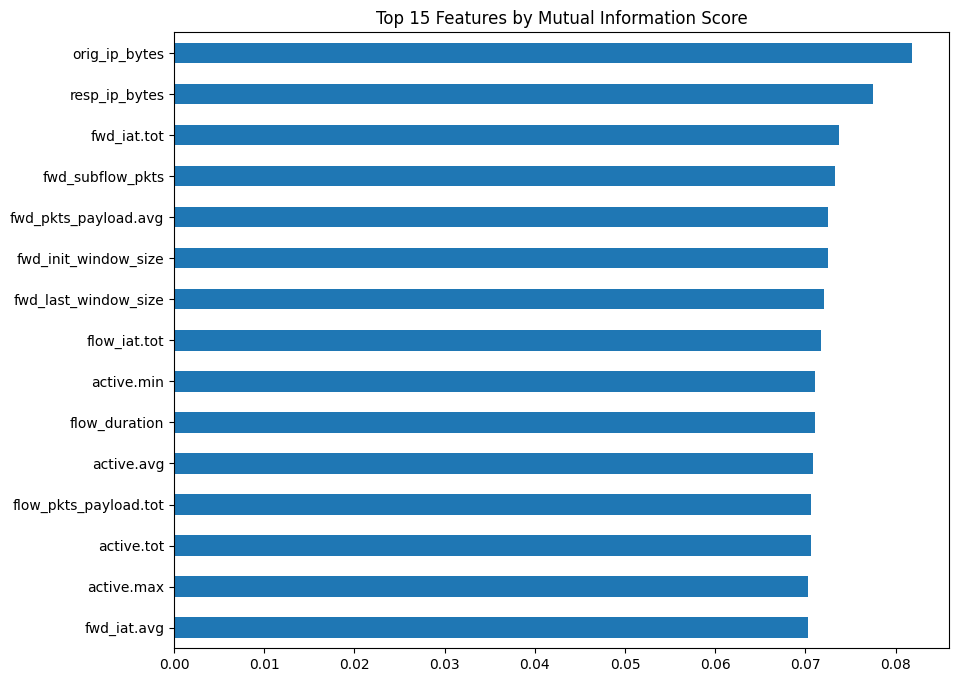

In [18]:
# selecting numerical columns only
X_sample = full_df.select_dtypes(include=['float64', 'int64']).drop(columns=['is_attack']).sample(20000)
y_sample = full_df.loc[X_sample.index, 'is_attack']

# calculate Mutual Information
importances = mutual_info_classif(X_sample, y_sample)
feature_importances = pd.Series(importances, index=X_sample.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
feature_importances.head(15).plot(kind='barh')
plt.title('Top 15 Features by Mutual Information Score')
plt.gca().invert_yaxis()
plt.show()

In [19]:
feature_importances

orig_ip_bytes           0.081835
resp_ip_bytes           0.077435
fwd_iat.tot             0.073754
fwd_subflow_pkts        0.073262
fwd_pkts_payload.avg    0.072517
                          ...   
idle.tot                0.000195
missed_bytes            0.000000
fwd_URG_flag_count      0.000000
flow_CWR_flag_count     0.000000
idle.max                0.000000
Length: 88, dtype: float64

PCA for dimentionality reduction

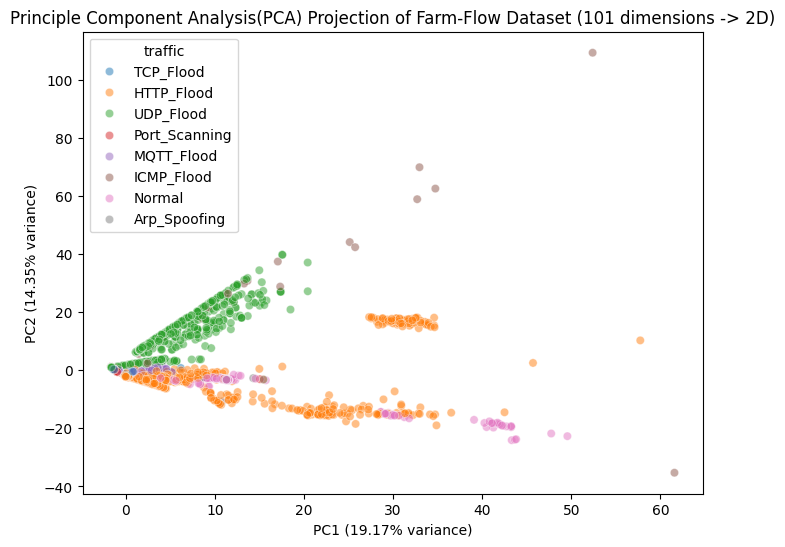

In [20]:
# Standardize and run PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample.fillna(0))
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
explained_var = pca.explained_variance_ratio_


# 2D projection
plt.figure(figsize=(8, 6))
sns.scatterplot(x=components[:,0], y=components[:,1], hue=full_df.loc[X_sample.index, 'traffic'], alpha=0.5)
plt.title('Principle Component Analysis(PCA) Projection of Farm-Flow Dataset (101 dimensions -> 2D)')
plt.xlabel(f'PC1 ({explained_var[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({explained_var[1]*100:.2f}% variance)')
plt.show()

MQTT Inspection (TCP port 1883)

In [21]:
mqtt_traffic = full_df[full_df['id.resp_p'] == 1883]

print(f"Total MQTT Flows: {len(mqtt_traffic)}")
print("\nMQTT Traffic Breakdown:")
print(mqtt_traffic['traffic'].value_counts())

Total MQTT Flows: 181471

MQTT Traffic Breakdown:
traffic
MQTT_Flood      132506
TCP_Flood        31583
Normal           17356
Arp_Spoofing        26
Name: count, dtype: int64


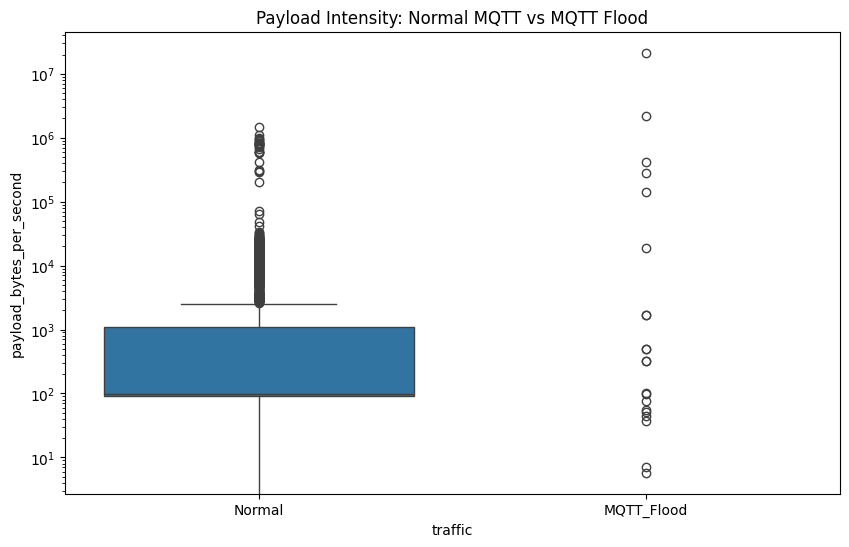

In [22]:
# Compare Payload Bytes during MQTT attacks
plt.figure(figsize=(10, 6))
sns.boxplot(x='traffic', y='payload_bytes_per_second', data=mqtt_traffic[mqtt_traffic['traffic'].isin(['Normal', 'MQTT_Flood'])])
plt.yscale('log')
plt.title('Payload Intensity: Normal MQTT vs MQTT Flood')
plt.show()

Connection State Analysis 
- In a farm, a sensor (Normal) should have a healthy "Handshake." Attackers usually leave connections "Half-Open."

In [23]:
# seeing the Connection States (Zeek 'conn_state' labels)
# OTH: other.
# RSTO: Connection attempt seen, then reset by the originator (client abort).
# RSTOS0: SYN sent, no reply, then reset by the originator.
# S0: Connection attempt seen, no reply (SYN sent, no SYN-ACK).
# S1: Connection established, not terminated (no FIN/RST observed).
# SHR: Connection established, then reset by the responder (server-side reset).

state_pivot = mqtt_traffic.groupby(['traffic', 'conn_state']).size().unstack().fillna(0)

# Normalize to percentages for a clear comparison
state_pct = state_pivot.div(state_pivot.sum(axis=1), axis=0) * 100
state_pct

conn_state,OTH,RSTO,RSTOS0,S0,S1,SHR
traffic,,,,,,
Arp_Spoofing,7.692308,11.538462,0.000000,0.000000,0.000000,80.769231
MQTT_Flood,22.066171,0.755437,0.000000,50.413566,26.764826,0.000000
Normal,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000
TCP_Flood,2.928791,19.323687,0.003166,22.068834,55.675522,0.000000


<Figure size 1200x700 with 0 Axes>

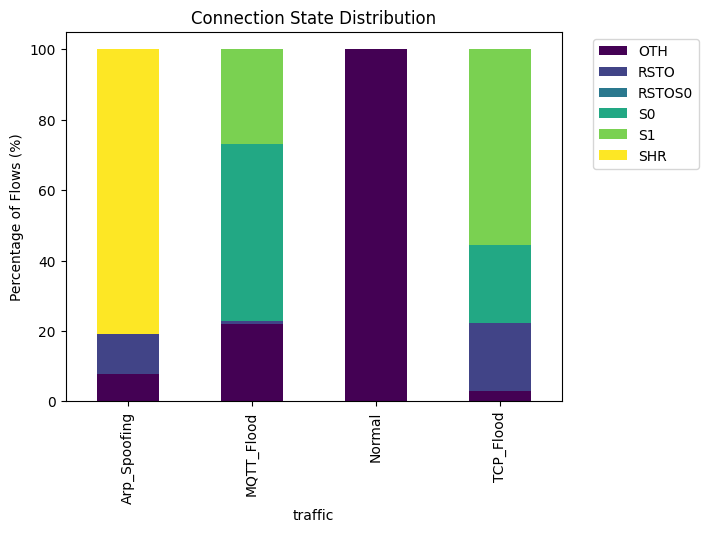

In [24]:
plt.figure(figsize=(12, 7))
state_pct.plot(kind='bar', stacked=True, colormap='viridis')
plt.title('Connection State Distribution') #Is the MQTT Handshake Healthy?
plt.ylabel('Percentage of Flows (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

Chcecking the flow

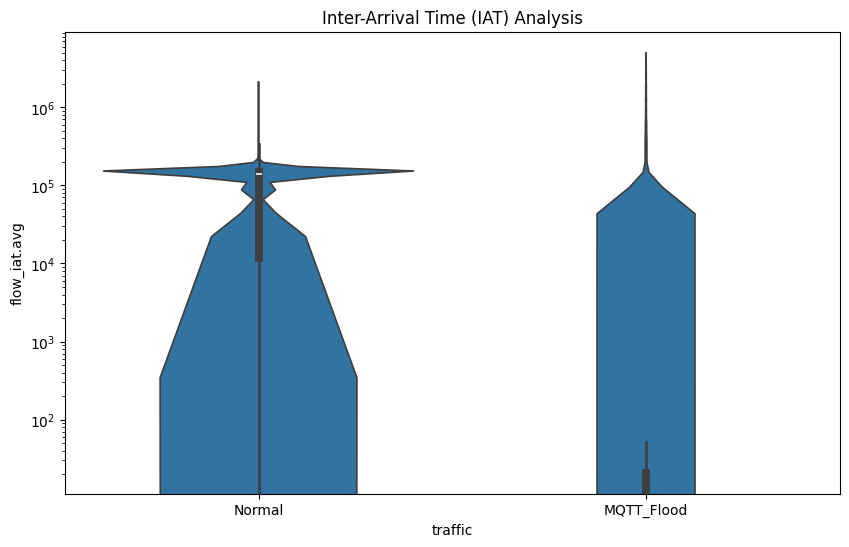

In [25]:
# 'flow_iat.avg' is the average time between packets in a flow.
plt.figure(figsize=(10, 6))
sns.violinplot(x='traffic', y='flow_iat.avg', data=mqtt_traffic[mqtt_traffic['traffic'].isin(['Normal', 'MQTT_Flood'])])
plt.yscale('log')
plt.title('Inter-Arrival Time (IAT) Analysis')
plt.show()

In [26]:
# How many unique source ports are used per traffic type?
port_variety = full_df.groupby('traffic')['id.orig_p'].nunique()
print("Unique Source Ports per Traffic Type;") #Indicating spoofing or botnet scale
print(port_variety.sort_values(ascending=False))

Unique Source Ports per Traffic Type;
traffic
TCP_Flood        65250
UDP_Flood        64834
MQTT_Flood       52305
ICMP_Flood       45873
HTTP_Flood       14116
Port_Scanning     9149
Normal            3470
Arp_Spoofing      1412
BotNet_DDOS         29
Name: id.orig_p, dtype: int64


Skewness and Kurtosis

In [27]:
# Select key numerical features
num_cols = ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'flow_iat.avg', 'payload_bytes_per_second']

skewness = full_df[num_cols].skew()
kurtosis = full_df[num_cols].kurtosis()

stats_df = pd.DataFrame({'Skewness': skewness, 'Kurtosis': kurtosis})
print("Distribution Statistics (High values > 3 indicate a need for Log-Scaling):")
print(stats_df)

Distribution Statistics (High values > 3 indicate a need for Log-Scaling):
                            Skewness       Kurtosis
flow_duration               9.943447     116.773638
fwd_pkts_tot              534.496518  297026.622003
bwd_pkts_tot              542.067291  328665.622426
flow_iat.avg               10.877131     181.626241
payload_bytes_per_second    6.234869      48.258915


Multicollinearity using VIF (Variance Information Factor)

In [28]:
# Pick a subset of 10 related features to test
subset_cols = ['fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 
               'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_duration', 'flow_iat.avg']

X_vif = full_df[subset_cols].fillna(0)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]

print("VIF Scores (Values > 10 indicate highly redundant features that should be dropped):")
print(vif_data.sort_values(by="VIF", ascending=False))

VIF Scores (Values > 10 indicate highly redundant features that should be dropped):
             feature          VIF
0       fwd_pkts_tot  5833.269222
2  fwd_data_pkts_tot  5807.733841
4   fwd_pkts_per_sec   396.765834
5   bwd_pkts_per_sec   396.730364
3  bwd_data_pkts_tot    35.535562
1       bwd_pkts_tot    34.731962
6      flow_duration     2.039865
7       flow_iat.avg     1.862489


In [29]:
print(full_df.columns.tolist())

['id.orig_h', 'id.orig_p', 'id.resp_h', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_paylo

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


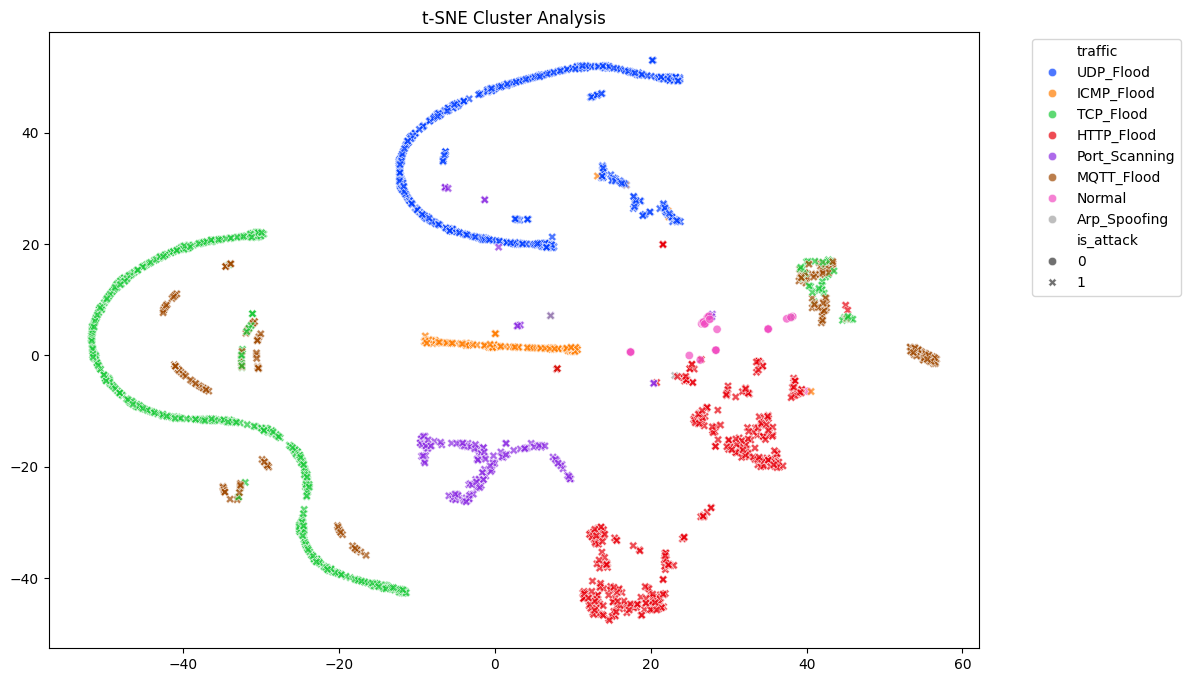

In [30]:
# Take a small balanced sample to make it fast
sample_df = full_df.sample(2000, random_state=42)
X_tsne = scaler.fit_transform(sample_df.select_dtypes(include=['float64', 'int64']).drop(columns=['is_attack']).fillna(0))

tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
results = tsne.fit_transform(X_tsne)

plt.figure(figsize=(12, 8))
sns.scatterplot(x=results[:,0], y=results[:,1], hue=sample_df['traffic'], style=sample_df['is_attack'], palette='bright', alpha=0.7)
plt.title('t-SNE Cluster Analysis') #check attack type separation
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

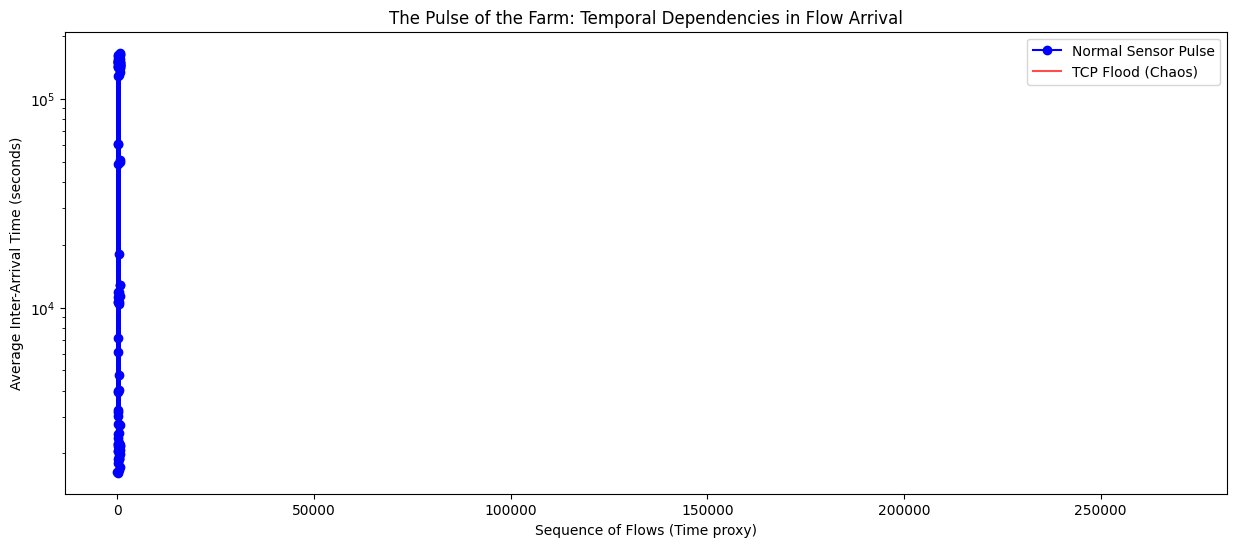

In [31]:
# We need to look at a sequence of flows from the same source
# Let's pick a specific sensor (Source IP) and plot its Inter-Arrival Time (IAT)
sample_sensor_ip = full_df[full_df['traffic'] == 'Normal']['id.orig_h'].iloc[0]
sensor_data = full_df[full_df['id.orig_h'] == sample_sensor_ip].head(100)

# Let's do the same for an attacker
attacker_data = full_df[full_df['traffic'] == 'TCP_Flood'].head(100)

plt.figure(figsize=(15, 6))
plt.plot(sensor_data.index, sensor_data['flow_iat.avg'], label='Normal Sensor Pulse', color='blue', marker='o')
plt.plot(attacker_data.index, attacker_data['flow_iat.avg'], label='TCP Flood (Chaos)', color='red', alpha=0.7)

plt.title('The Pulse of the Farm: Temporal Dependencies in Flow Arrival')
plt.ylabel('Average Inter-Arrival Time (seconds)')
plt.xlabel('Sequence of Flows (Time proxy)')
plt.legend()
plt.yscale('log')
plt.show()

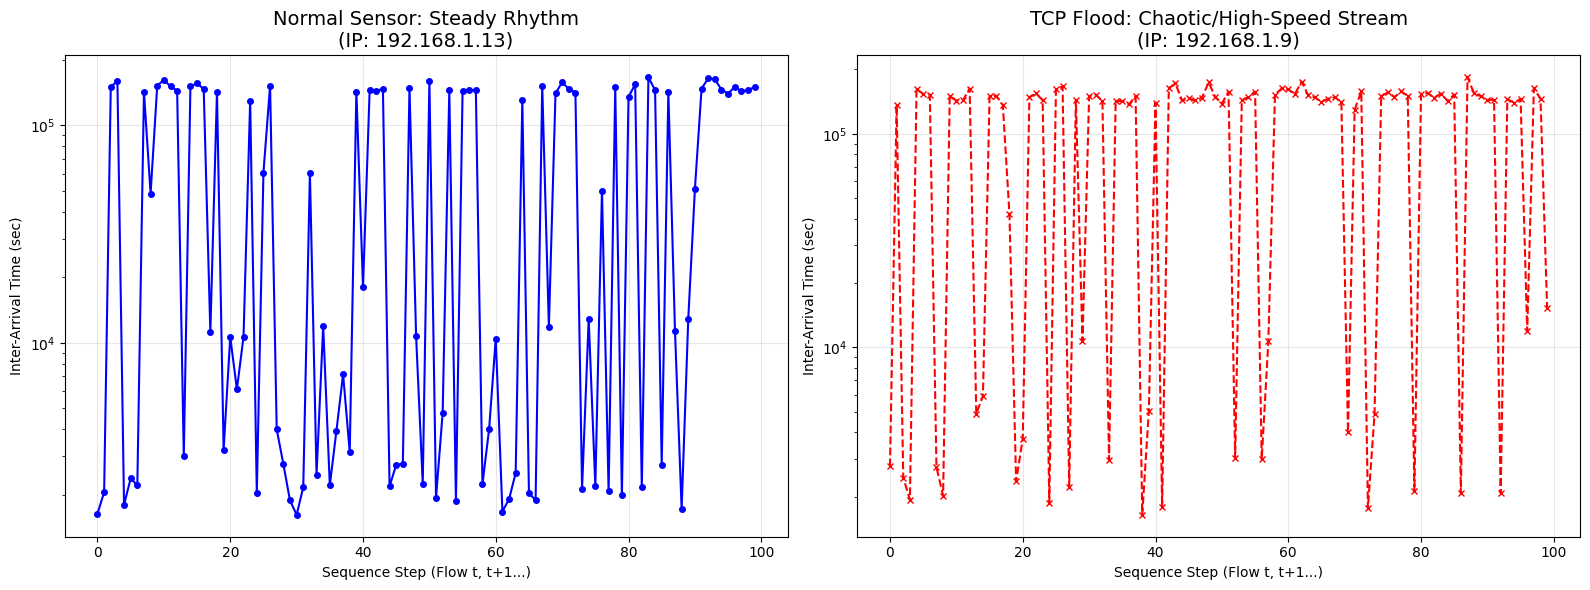

In [32]:
# 1. Pick a specific Normal Sensor and a specific Attacker
normal_ip = full_df[full_df['traffic'] == 'Normal']['id.orig_h'].iloc[0]
attacker_ip = full_df[full_df['traffic'] == 'TCP_Flood']['id.orig_h'].iloc[0]

# 2. Get 100 CONSECUTIVE flows for each (simulating an LSTM window)
norm_window = full_df[full_df['id.orig_h'] == normal_ip].head(100).reset_index(drop=True)
atk_window = full_df[full_df['id.orig_h'] == attacker_ip].head(100).reset_index(drop=True)

# 3. Plot them side-by-side to show the "Rhythm"
plt.figure(figsize=(16, 6))

# Subplot 1: Normal Traffic (The "Heartbeat")
plt.subplot(1, 2, 1)
plt.plot(norm_window.index, norm_window['flow_iat.avg'], color='blue', marker='o', linestyle='-', markersize=4)
plt.title(f'Normal Sensor: Steady Rhythm\n(IP: {normal_ip})', fontsize=14)
plt.ylabel('Inter-Arrival Time (sec)')
plt.xlabel('Sequence Step (Flow t, t+1...)')
plt.grid(True, alpha=0.3)
plt.yscale('log')

# Subplot 2: Attack Traffic (The "Flood")
plt.subplot(1, 2, 2)
plt.plot(atk_window.index, atk_window['flow_iat.avg'], color='red', marker='x', linestyle='--', markersize=4)
plt.title(f'TCP Flood: Chaotic/High-Speed Stream\n(IP: {attacker_ip})', fontsize=14)
plt.ylabel('Inter-Arrival Time (sec)')
plt.xlabel('Sequence Step (Flow t, t+1...)')
plt.grid(True, alpha=0.3)
plt.yscale('log')

plt.tight_layout()
plt.show()

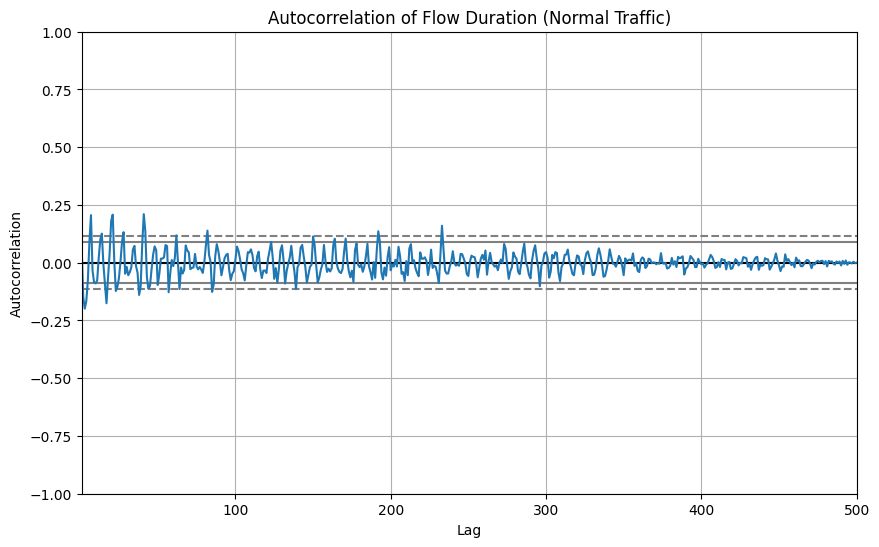

In [33]:
plt.figure(figsize=(10, 6))
# We check if the 'flow_duration' of one packet is related to the previous packets
autocorrelation_plot(full_df[full_df['traffic'] == 'Normal']['flow_duration'].head(500))
plt.title('Autocorrelation of Flow Duration (Normal Traffic)')
plt.show()

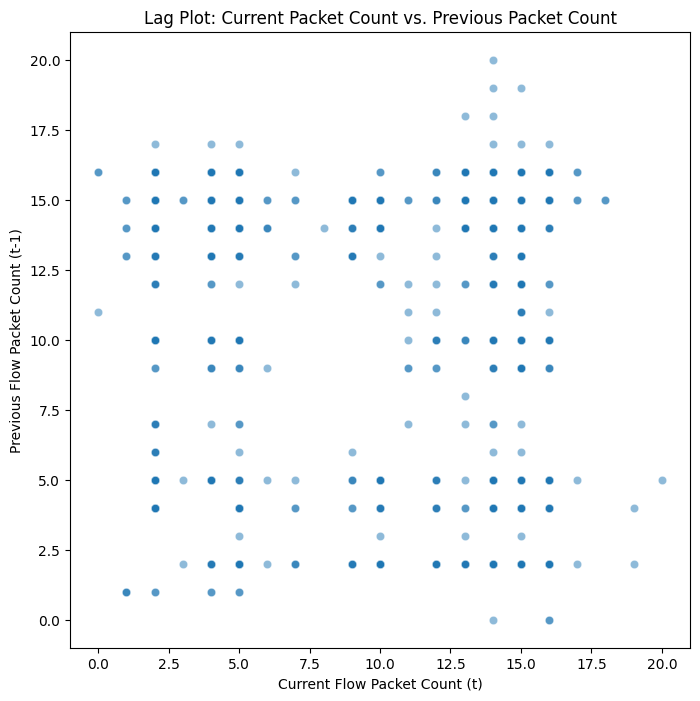

In [34]:
# Create a lagged version of a feature (what the value was 1 step ago)
temp_df = full_df[full_df['traffic'] == 'Normal'].copy()
temp_df['fwd_pkts_lag1'] = temp_df['fwd_pkts_tot'].shift(1)

plt.figure(figsize=(8, 8))
sns.scatterplot(x='fwd_pkts_tot', y='fwd_pkts_lag1', data=temp_df.head(1000), alpha=0.5)
plt.title('Lag Plot: Current Packet Count vs. Previous Packet Count')
plt.xlabel('Current Flow Packet Count (t)')
plt.ylabel('Previous Flow Packet Count (t-1)')
plt.show()

**Preprocessing**

**Log-Transformation**

Extreme skewness in `flow_duration` and `payload_bytes` were found. Since Deep Learning uses gradient descent, large outliers can cause gradients to explode. we apply the transformation:

`log(x + 1)`

to all high-skew features.

In [4]:
# Identify numerical columns
numerical_cols = full_df.select_dtypes(include=['float64', 'int64']).columns.tolist()
# Remove target labels from transformation list
if 'is_attack' in numerical_cols: numerical_cols.remove('is_attack')

# Calculate skewness before transformation
skew_before = full_df[numerical_cols].skew().sort_values(ascending=False)

# Select columns with Skewness > 1.0
high_skew_cols = skew_before[abs(skew_before) > 1.0].index.tolist()

print(f"Applying Log-Transformation to {len(high_skew_cols)} highly skewed features...")
print(f"Sample columns: {high_skew_cols[:5]}")

Applying Log-Transformation to 79 highly skewed features...
Sample columns: ['flow_pkts_payload.avg', 'flow_pkts_payload.tot', 'flow_pkts_payload.max', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max']


In [5]:
original_duration = full_df['flow_duration'].copy()

# Apply log(x+1) transformation
for col in high_skew_cols:
    full_df[col] = np.log1p(full_df[col])

skew_after = full_df[high_skew_cols].skew().sort_values(ascending=False)
print("\nSkewness Improvement Example (flow_duration):")
print(f"Before: {skew_before['flow_duration']:.2f}")
print(f"After:  {skew_after['flow_duration']:.2f}")


Skewness Improvement Example (flow_duration):
Before: 9.94
After:  4.53


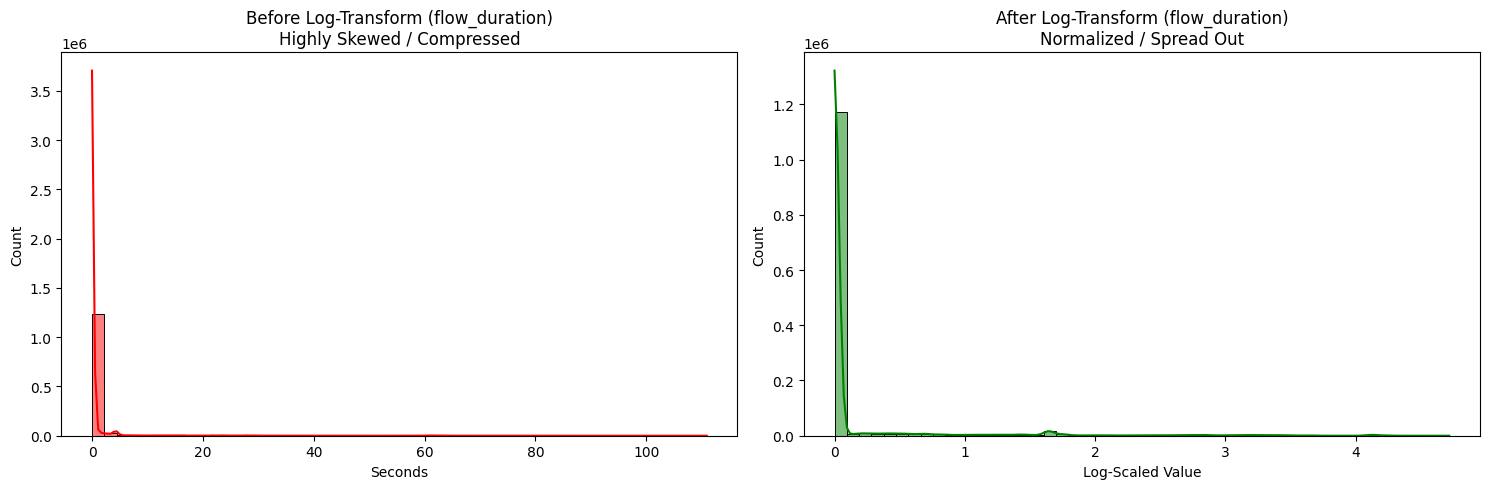

In [14]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
sns.histplot(original_duration, bins=50, kde=True, color='red')
plt.title('Before Log-Transform (flow_duration)\nHighly Skewed / Compressed', fontsize=12)
plt.xlabel('Seconds')

plt.subplot(1, 2, 2)
sns.histplot(full_df['flow_duration'], bins=50, kde=True, color='green')
plt.title('After Log-Transform (flow_duration)\nNormalized / Spread Out', fontsize=12)
plt.xlabel('Log-Scaled Value')

plt.tight_layout()
plt.show()

**One-Hot Encoding**
Used instead of categorical to avoid misleading model

In [15]:
# Identify categorical columns
full_df['service'] = full_df['service'].replace('-', 'unknown')

cat_cols = ['proto', 'service', 'conn_state']

# Perform One-Hot Encoding
full_df = pd.get_dummies(full_df, columns=cat_cols, prefix=cat_cols)

# Ensure the new columns are integers (0 or 1) rather than Booleans
new_cat_cols = [c for c in full_df.columns if any(p in c for p in cat_cols)]
full_df[new_cat_cols] = full_df[new_cat_cols].astype(int)

print(f"One-Hot Encoding complete. New dataframe shape: {full_df.shape}")

One-Hot Encoding complete. New dataframe shape: (1309887, 122)


**Feature selection**

Using correlation

In [16]:
# Select only numerical columns for correlation check
numerical_df = full_df.select_dtypes(include=[np.number]).drop(columns=['is_attack'], errors='ignore')

corr_matrix = numerical_df.corr().abs()

# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

print(f"Redundant features identified (>0.95 correlation): {len(to_drop)}")
print(f"Dropping: {to_drop}")

full_df = full_df.drop(columns=to_drop)
print(f"Final feature count: {full_df.shape[1]}")

Redundant features identified (>0.95 correlation): 38
Dropping: ['bwd_pkts_per_sec', 'flow_pkts_per_sec', 'fwd_header_size_max', 'bwd_header_size_min', 'bwd_header_size_max', 'fwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.max', 'fwd_iat.tot', 'fwd_iat.avg', 'bwd_iat.tot', 'bwd_iat.avg', 'flow_iat.tot', 'flow_iat.avg', 'bwd_subflow_pkts', 'fwd_subflow_bytes', 'bwd_subflow_bytes', 'fwd_bulk_packets', 'bwd_bulk_packets', 'fwd_bulk_rate', 'active.max', 'active.tot', 'active.avg', 'idle.max', 'idle.tot', 'idle.avg', 'fwd_last_window_size', 'bwd_last_window_size', 'proto_udp']
Final feature count: 84


In [ ]:
print()

**Variance Inflation Factor (VIF) Check**
While correlation looks at pairs, VIF looks at how much one feature can be predicted by all other features combined.

In [17]:
# We take a sample because VIF is computationally expensive 1309887
X_vif_check = full_df.select_dtypes(include=[np.number]).drop(columns=['is_attack']).sample(5000).fillna(0)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif_check.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif_check.values, i) for i in range(len(X_vif_check.columns))]

# VIF > 10 as the cutof
high_vif = vif_data[vif_data['VIF'] > 10].sort_values(by='VIF', ascending=False)
print("Features with High VIF (Potential for further pruning):")
print(high_vif.head(20))

/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Features with High VIF (Potential for further pruning):
                 feature         VIF
63       conn_state_RSTO         inf
62        conn_state_REJ         inf
67         conn_state_S1         inf
70         conn_state_SF         inf
71         conn_state_SH         inf
72        conn_state_SHR         inf
61        conn_state_OTH         inf
60       service_unknown         inf
56          service_mqtt         inf
55          service_http         inf
66         conn_state_S0         inf
64     conn_state_RSTOS0         inf
9           bwd_pkts_tot  887.615063
8           fwd_pkts_tot  613.071510
16   bwd_header_size_tot  580.550187
14   fwd_header_size_tot  490.660039
13         down_up_ratio  266.919282
37          flow_iat.max  238.925455
26  fwd_pkts_payload.max  195.577843
10     fwd_data_pkts_tot  126.863445


In [18]:
# 1. Resolve the Dummy Variable Trap (Drop one from each encoded set)
cols_to_drop_vif = [
    'conn_state_OTH',   # Reference for connection state
    'service_unknown',  # Reference for service type
]

# Drop Physical Redundancies (Keep counts, drop header sizes/ratios)
# These are highly redundant with fwd_pkts_tot and bwd_pkts_tot
redundant_physical = [
    'fwd_header_size_tot', 
    'bwd_header_size_tot',
    'fwd_header_size_max',
    'bwd_header_size_max',
    'down_up_ratio' # This is just bwd/fwd, redundant with the counts themselves
]

# Handle high IAT redundancy
# If flow_duration is kept, flow_iat.tot is usually redundant
redundant_temporal = ['flow_iat.max', 'fwd_iat.tot', 'bwd_iat.tot']

# Combine all drops
final_drops = cols_to_drop_vif + redundant_physical + redundant_temporal
final_drops = [c for c in final_drops if c in full_df.columns] # Ensure they exist

full_df = full_df.drop(columns=final_drops)

print(f"Pruned {len(final_drops)} features based on VIF analysis.")
print(f"Remaining features: {full_df.shape[1]}")

# Re-run a quick VIF on the most important columns
# to ensure we've dropped the 'inf'
X_check = full_df.select_dtypes(include=[np.number]).drop(columns=['is_attack']).sample(5000).fillna(0)
vif_final = pd.DataFrame()
vif_final["feature"] = X_check.columns
vif_final["VIF"] = [variance_inflation_factor(X_check.values, i) for i in range(len(X_check.columns))]

print("\nTop 5 VIFs after cleaning:")
print(vif_final.sort_values(by='VIF', ascending=False).head(5))

Pruned 6 features based on VIF analysis.
Remaining features: 78


/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1784: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.uncentered_tss



Top 5 VIFs after cleaning:
                 feature         VIF
17    bwd_PSH_flag_count         inf
11     bwd_data_pkts_tot         inf
25  bwd_pkts_payload.min         inf
8           fwd_pkts_tot  380.756390
36      fwd_subflow_pkts  265.966794


In [19]:
# Drop non-numeric ID columns that aren't useful for general deep learning
id_cols = ['id.orig_h', 'id.resp_h', 'traffic', 'history', 'tunnel_parents'] 
# We keep 'traffic' separately if we want multi-class labels later, but drop from X
full_df = full_df.drop(columns=[c for c in id_cols if c in full_df.columns])

In [20]:
full_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309887 entries, 0 to 1309886
Data columns (total 73 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   id.orig_p                 1309887 non-null  int64  
 1   id.resp_p                 1309887 non-null  float64
 2   duration                  1309887 non-null  object 
 3   orig_bytes                1309887 non-null  object 
 4   resp_bytes                1309887 non-null  object 
 5   local_orig                1309887 non-null  object 
 6   local_resp                1309887 non-null  object 
 7   missed_bytes              1309887 non-null  float64
 8   orig_pkts                 1309887 non-null  float64
 9   orig_ip_bytes             1309887 non-null  float64
 10  resp_pkts                 1309887 non-null  float64
 11  resp_ip_bytes             1309887 non-null  float64
 12  flow_duration             1309887 non-null  float64
 13  fwd_pkts_tot              1

In [21]:
obj_cols = ['duration', 'orig_bytes', 'resp_bytes', 'local_orig', 'local_resp']
for col in obj_cols:
    full_df[col] = pd.to_numeric(full_df[col], errors='coerce').fillna(0)

# Final drop of categorical/ID columns that might have slipped through
# We drop 'id.orig_p' because source ports are usually random (ephemeral)
# but we keep 'id.resp_p' because it identifies the service (e.g., 1883 for MQTT)
if 'id.orig_p' in full_df.columns:
    full_df = full_df.drop(columns=['id.orig_p'])

full_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309887 entries, 0 to 1309886
Data columns (total 72 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   id.resp_p                 1309887 non-null  float64
 1   duration                  1309887 non-null  float64
 2   orig_bytes                1309887 non-null  float64
 3   resp_bytes                1309887 non-null  float64
 4   local_orig                1309887 non-null  float64
 5   local_resp                1309887 non-null  float64
 6   missed_bytes              1309887 non-null  float64
 7   orig_pkts                 1309887 non-null  float64
 8   orig_ip_bytes             1309887 non-null  float64
 9   resp_pkts                 1309887 non-null  float64
 10  resp_ip_bytes             1309887 non-null  float64
 11  flow_duration             1309887 non-null  float64
 12  fwd_pkts_tot              1309887 non-null  float64
 13  bwd_pkts_tot              1

**Peephole LSTM Specific Preprocessing**

In a standard LSTM, the gates only see the hidden state (`h_{t-1}`) and the input (`x_t`). In a Peephole LSTM, the gates are also connected directly to the cell state (`c_t`). This allows the model to learn exactly how much "time" has passed or how many "packets" have accumulated within the internal memory before triggering a gate.

If data isn't properly scaled, the cell state can become saturated, and the peephole connections will effectively receive noisy or uninformative signals.

In [6]:
# Binary target
y_binary = full_df['is_attack'].astype('int8')

# Traffic classes for balancing
y_traffic = full_df['traffic'].copy()

print(y_traffic.value_counts())

traffic
TCP_Flood        381765
UDP_Flood        296553
HTTP_Flood       265025
MQTT_Flood       132506
Port_Scanning    126700
ICMP_Flood        76849
Normal            27458
Arp_Spoofing       2967
BotNet_DDOS          64
Name: count, dtype: int64


In [7]:
X_train, X_test, y_train_traffic, y_test_traffic, y_train_binary, y_test_binary = train_test_split(
    X_scaled,
    y_traffic,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_traffic
)

NameError: name 'X_scaled' is not defined

In [55]:
from collections import Counter

print("Before balancing:")
print(Counter(y_train_traffic))

Before balancing:
Counter({'TCP_Flood': 305412, 'UDP_Flood': 237242, 'HTTP_Flood': 212020, 'MQTT_Flood': 106005, 'Port_Scanning': 101360, 'ICMP_Flood': 61479, 'Normal': 21966, 'Arp_Spoofing': 2374, 'BotNet_DDOS': 51})


In [ ]:
TARGET_SIZE = 10000

under_strategy = {
    cls: TARGET_SIZE
    for cls, count in Counter(y_train_traffic).items()
    if count > TARGET_SIZE
}

over_strategy = {
    cls: TARGET_SIZE
    for cls, count in Counter(y_train_traffic).items()
    if count < TARGET_SIZE
}

In [56]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ('under', RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )),
    ('smote', SMOTE(
        sampling_strategy=over_strategy,
        random_state=42,
        k_neighbors=5
    ))
])

X_train_bal, y_train_bal_traffic = pipeline.fit_resample(
    X_train,
    y_train_traffic
)

In [58]:
#recreate binary lable
y_train_bal_binary = (
    y_train_bal_traffic != "Normal"
).astype("int8")

In [59]:
print(pd.Series(y_train_bal_traffic).value_counts())

traffic
Arp_Spoofing     50000
BotNet_DDOS      50000
HTTP_Flood       50000
ICMP_Flood       50000
MQTT_Flood       50000
Normal           50000
Port_Scanning    50000
TCP_Flood        50000
UDP_Flood        50000
Name: count, dtype: int64


In [52]:
# Separate Features and Label
# Ensure we are using float32 for RAM efficiency
X = full_df.drop(columns=['is_attack']).astype('float32')
y = full_df['is_attack'].values.astype('int8')

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Sanity Check using 'flow_duration'
dur_idx = X.columns.get_loc('flow_duration')
print(f"Data scaled. Feature 'flow_duration' Mean: {X_scaled[:, dur_idx].mean():.2f}, Std: {X_scaled[:, dur_idx].std():.2f}")

ValueError: could not convert string to float: '192.168.1.13'

Applying SMOTE

In [25]:
# Binary target
y_binary = full_df['is_attack'].astype('int8')

# Traffic classes for balancing
y_traffic = full_df['traffic'].copy()

print(y_traffic.value_counts())

traffic
TCP_Flood        381765
UDP_Flood        296553
HTTP_Flood       265025
MQTT_Flood       132506
Port_Scanning    126700
ICMP_Flood        76849
Normal            27458
Arp_Spoofing       2967
BotNet_DDOS          64
Name: count, dtype: int64


Train test split before smote

In [26]:
X_train, X_test, y_train_traffic, y_test_traffic, y_train_binary, y_test_binary = train_test_split(
    X_scaled,
    y_traffic,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_traffic
)

In [27]:
from collections import Counter

print("Before balancing:")
print(Counter(y_train_traffic))

Before balancing:
Counter({'TCP_Flood': 305412, 'UDP_Flood': 237242, 'HTTP_Flood': 212020, 'MQTT_Flood': 106005, 'Port_Scanning': 101360, 'ICMP_Flood': 61479, 'Normal': 21966, 'Arp_Spoofing': 2374, 'BotNet_DDOS': 51})


In [28]:
TARGET_SIZE = 50000

under_strategy = {
    cls: TARGET_SIZE
    for cls, count in Counter(y_train_traffic).items()
    if count > TARGET_SIZE
}

over_strategy = {
    cls: TARGET_SIZE
    for cls, count in Counter(y_train_traffic).items()
    if count < TARGET_SIZE
}

In [29]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ('under', RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )),
    ('smote', SMOTE(
        sampling_strategy=over_strategy,
        random_state=42,
        k_neighbors=5
    ))
])

X_train_bal, y_train_bal_traffic = pipeline.fit_resample(
    X_train,
    y_train_traffic
)

In [30]:
#recreate binary lable
y_train_bal_binary = (
    y_train_bal_traffic != "Normal"
).astype("int8")

In [31]:
print(pd.Series(y_train_bal_traffic).value_counts())

traffic
Arp_Spoofing     50000
BotNet_DDOS      50000
HTTP_Flood       50000
ICMP_Flood       50000
MQTT_Flood       50000
Normal           50000
Port_Scanning    50000
TCP_Flood        50000
UDP_Flood        50000
Name: count, dtype: int64


In [32]:
y_train_bal_traffic.info()

<class 'pandas.core.series.Series'>
RangeIndex: 450000 entries, 0 to 449999
Series name: traffic
Non-Null Count   Dtype 
--------------   ----- 
450000 non-null  object
dtypes: object(1)
memory usage: 3.4+ MB


In [61]:
# Create Sequences (Memory Efficient)
def create_sequences_fast(data, labels, window_size=10):
    # Pre-allocate memory to avoid slow list appending
    n_samples = len(data) - window_size
    n_features = data.shape[1]
    
    X_seq = np.zeros((n_samples, window_size, n_features), dtype='float32')
    y_seq = np.zeros((n_samples), dtype='int8')
    
    for i in range(n_samples):
        X_seq[i] = data[i : i + window_size]
        y_seq[i] = labels[i + window_size]
        
    return X_seq, y_seq

WINDOW_SIZE = 10
print(f"Creating sequences with window size {WINDOW_SIZE}...")
#X_final, y_final = create_sequences_fast(X_scaled, y, window_size=WINDOW_SIZE)
X_final, y_final = create_sequences_fast(
    X_train_bal,
    y_train_bal_binary,
    window_size=WINDOW_SIZE
)
print(f"Final 3D Tensor Shape: {X_final.shape}")

Creating sequences with window size 10...
Final 3D Tensor Shape: (449990, 10, 71)


In [62]:
# Split: 70% Train, 15% Val, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X_final, y_final, test_size=0.3, random_state=42, stratify=y_final
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Pre-processing Complete.")
print(f"Training:   {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Testing:    {X_test.shape}")

Pre-processing Complete.
Training:   (314993, 10, 71)
Validation: (67498, 10, 71)
Testing:    (67499, 10, 71)


**Defining the Peephole LSTM Architecture**
- Since Keras's default LSTM layer does not support Peephole connections (they were removed in newer versions for speed), we have to use the `LSTMCell` within an `RNN` layer to enable them.

**Custom Peephole Cell**

In a Peephole LSTM, the gates (`i`, `f`, `o`) use the cell state (`c`) to make their decisions. We will create a custom class that inherits from `tf.keras.layers.Layer`.

In [63]:
import tensorflow as tf
from tensorflow.keras import layers, models, initializers

class PeepholeLSTMCell(layers.Layer):
    def __init__(self, units, **kwargs):
        self.units = units
        self.state_size = [units, units] # [hidden_state, cell_state]
        super(PeepholeLSTMCell, self).__init__(**kwargs)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        
        # Standard weights for Input, Forget, and Output gates
        self.kernel = self.add_weight(shape=(input_dim, self.units * 4), name='kernel', initializer='glorot_uniform')
        self.recurrent_kernel = self.add_weight(shape=(self.units, self.units * 4), name='recurrent_kernel', initializer='orthogonal')
        self.bias = self.add_weight(shape=(self.units * 4,), name='bias', initializer='zeros')
        
        # THE PEEPHOLE WEIGHTS (V matrices)
        # These allow gates to see the Cell State directly
        self.peephole_i = self.add_weight(shape=(self.units,), name='peephole_i', initializer='zeros')
        self.peephole_f = self.add_weight(shape=(self.units,), name='peephole_f', initializer='zeros')
        self.peephole_o = self.add_weight(shape=(self.units,), name='peephole_o', initializer='zeros')
        
        self.built = True

    def call(self, inputs, states):
        h_tm1, c_tm1 = states # States from previous time step

        # Compute Gates (Input, Forget, Candidate, Output)
        z = tf.matmul(inputs, self.kernel) + tf.matmul(h_tm1, self.recurrent_kernel) + self.bias
        z_i, z_f, z_c, z_o = tf.split(z, num_or_size_splits=4, axis=1)

        # Apply Peephole connections to Input and Forget gates (using c_tm1)
        i = tf.sigmoid(z_i + self.peephole_i * c_tm1)
        f = tf.sigmoid(z_f + self.peephole_f * c_tm1)
        
        # Calculate new Cell State
        c = f * c_tm1 + i * tf.tanh(z_c)
        
        # Apply Peephole connection to Output gate (using the updated c)
        o = tf.sigmoid(z_o + self.peephole_o * c)
        
        # Final Hidden State
        h = o * tf.tanh(c)
        
        return h, [h, c]

# Now we build the model using our custom cell
model_peephole = models.Sequential([
    layers.RNN(PeepholeLSTMCell(64), input_shape=(X_train.shape[1], X_train.shape[2])),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_peephole.compile(
    optimizer='adam', 
    loss='binary_crossentropy', 
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model_peephole.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnn_1 (RNN)                     │ (None, 64)             │        35,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,377 (146.00 KB)

 Trainable params: 37,249 (145.50 KB)

 Non-trainable params: 128 (512.00 B)

**Handling the Imbalance (Class Weights)**
From data analysis, we have vastly more Attacks than Normal traffic. If a model is trained normally, it might just learn to say "Attack" every time.

In [64]:
from sklearn.utils import class_weight

# Calculate weights based on the training labels
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {0: weights[0], 1: weights[1]}
print(f"Class Weights applied: {class_weights}")

Class Weights applied: {0: np.float64(4.4999), 1: np.float64(0.5625015625390635)}


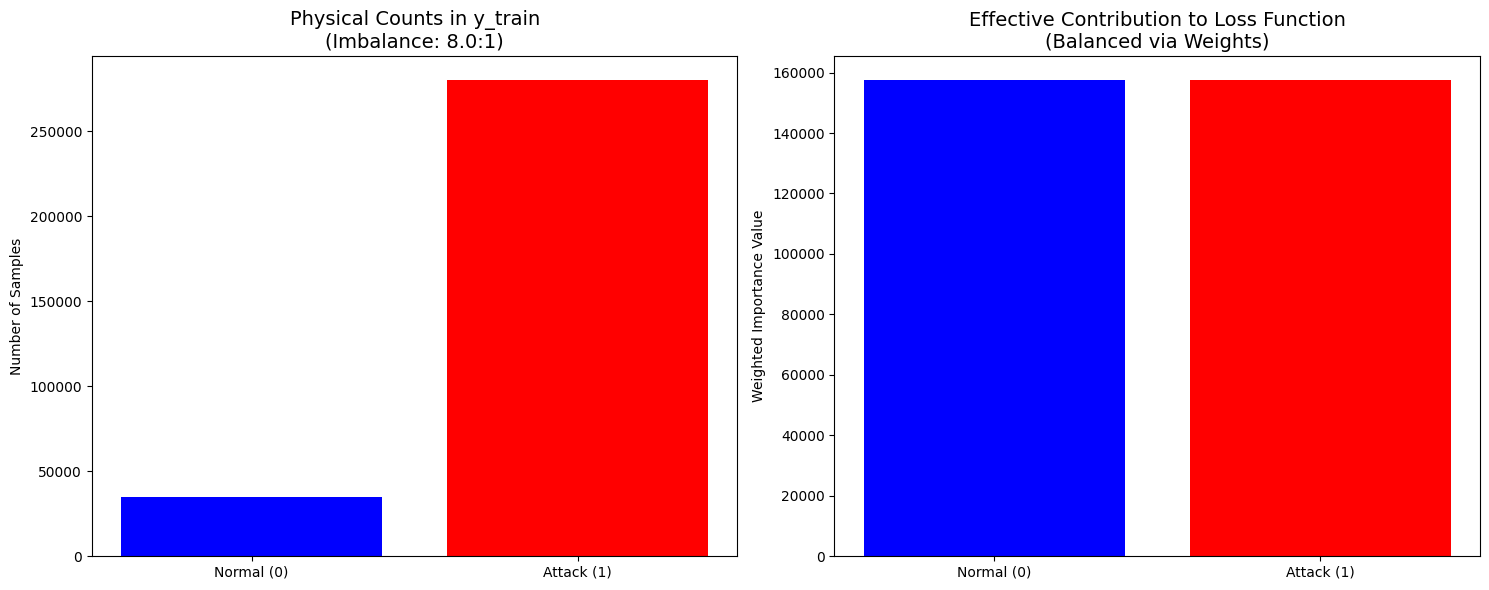

Normal Class Weight: 4.4999 (Multiplier)
Attack Class Weight: 0.5625 (Multiplier)


In [37]:
# Get the actual counts in training data
unique, counts = np.unique(y_train, return_counts=True)
physical_counts = dict(zip(unique, counts))

# Calculate the 'Effective' importance (Count * Weight)
# class_weights[0] is the weight for 'Normal', class_weights[1] for 'Attack'
effective_importance = {
    0: physical_counts[0] * class_weights[0],
    1: physical_counts[1] * class_weights[1]
}

# Plot the comparison
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Physical Imbalance
ax[0].bar(['Normal (0)', 'Attack (1)'], physical_counts.values(), color=['blue', 'red'])
ax[0].set_title(f"Physical Counts in y_train\n(Imbalance: {physical_counts[1]/physical_counts[0]:.1f}:1)", fontsize=14)
ax[0].set_ylabel("Number of Samples")

# Effective Importance (What the Model 'Sees')
ax[1].bar(['Normal (0)', 'Attack (1)'], effective_importance.values(), color=['blue', 'red'])
ax[1].set_title("Effective Contribution to Loss Function\n(Balanced via Weights)", fontsize=14)
ax[1].set_ylabel("Weighted Importance Value")

plt.tight_layout()
plt.show()

print(f"Normal Class Weight: {class_weights[0]:.4f} (Multiplier)")
print(f"Attack Class Weight: {class_weights[1]:.4f} (Multiplier)")

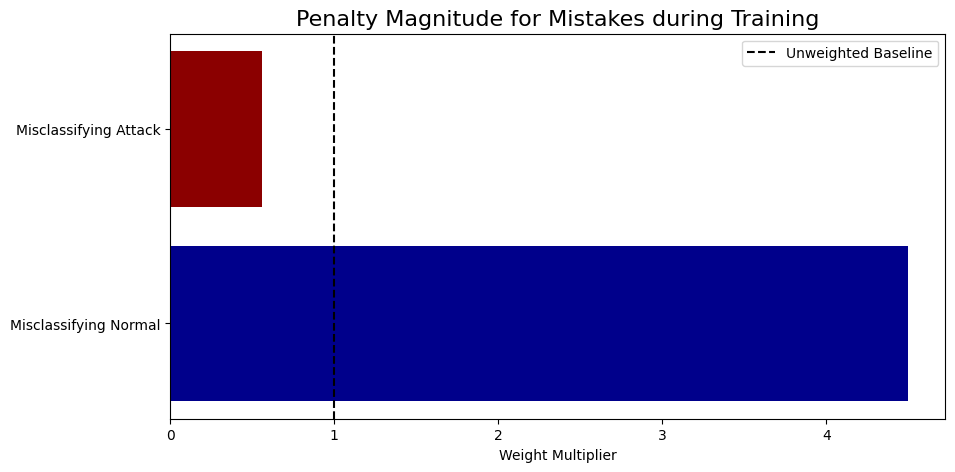

In [41]:
plt.figure(figsize=(10, 5))
labels = ['Misclassifying Normal', 'Misclassifying Attack']
penalties = [class_weights[0], class_weights[1]]

plt.barh(labels, penalties, color=['darkblue', 'darkred'])
plt.title("Penalty Magnitude for Mistakes during Training", fontsize=16)
plt.xlabel("Weight Multiplier")
plt.axvline(x=1.0, color='black', linestyle='--', label='Unweighted Baseline')
plt.legend()
plt.show()

In [65]:
# Train
history = model_peephole.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3,
    batch_size=1024, # Increased for speed on 1.3M rows
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    ],
    verbose=1
)

Epoch 1/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9519 - auc: 0.9944 - loss: 0.1238 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 9.4553e-04
Epoch 2/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9999 - auc: 0.9999 - loss: 8.9452e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.0255e-04
Epoch 3/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9999 - auc: 1.0000 - loss: 5.0470e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.4285e-05


2110/2110 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


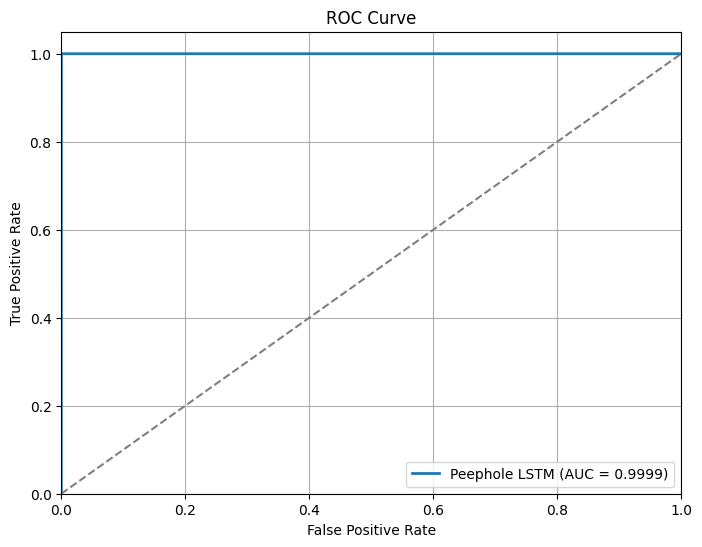

In [66]:
from sklearn.metrics import roc_curve, auc
# Probabilities
y_pred_prob = model_peephole.predict(X_test).ravel()

# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, lw=2, label=f'Peephole LSTM (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


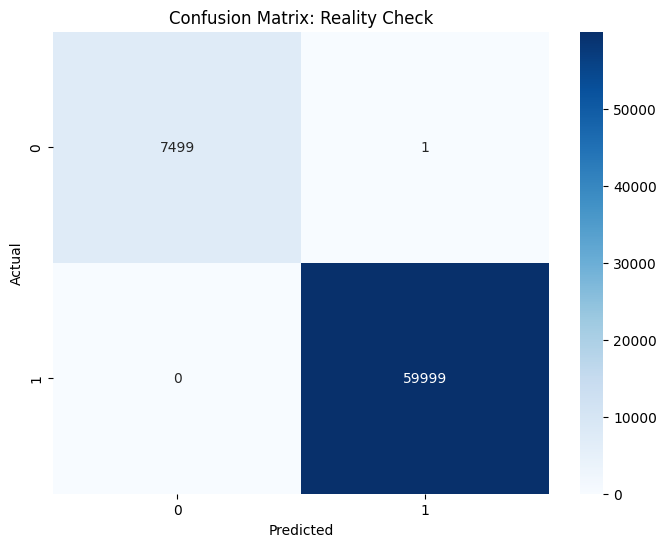

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7500
           1       1.00      1.00      1.00     59999

    accuracy                           1.00     67499
   macro avg       1.00      1.00      1.00     67499
weighted avg       1.00      1.00      1.00     67499



In [67]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions on the Test set
y_pred_prob = model_peephole.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Reality Check')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred))

**Minimal GRU**

In [68]:
class MinimalGRUCell(layers.Layer):
    def __init__(self, units, **kwargs):
        self.units = units
        self.state_size = units
        super(MinimalGRUCell, self).__init__(**kwargs)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        # MGU has only ONE gate (f)
        self.kernel = self.add_weight(shape=(input_dim, self.units * 2), name='kernel')
        self.recurrent_kernel = self.add_weight(shape=(self.units, self.units * 2), name='recurrent_kernel')
        self.bias = self.add_weight(shape=(self.units * 2,), name='bias', initializer='zeros')
        self.built = True

    def call(self, inputs, states):
        h_tm1 = states[0]
        
        # Linear transformations
        z = tf.matmul(inputs, self.kernel) + tf.matmul(h_tm1, self.recurrent_kernel) + self.bias
        z_f, z_h = tf.split(z, num_or_size_splits=2, axis=1)
        
        # The single gate: Forget/Update merged
        f = tf.sigmoid(z_f)
        
        # Candidate hidden state
        h_tilde = tf.tanh(z_h * f) # Only the candidate state uses the gate
        
        # New hidden state: (1-f)*h_tm1 + f*h_tilde
        h = (1 - f) * h_tm1 + f * h_tilde
        return h, [h]

# Build the MGU Model
model_mgu = models.Sequential([
    layers.RNN(MinimalGRUCell(64), input_shape=(X_train.shape[1], X_train.shape[2])),
    layers.BatchNormalization(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_mgu.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

model_mgu.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnn_2 (RNN)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,649 (76.75 KB)

 Non-trainable params: 128 (512.00 B)

In [70]:
# Train the MGU
history_mgu = model_mgu.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3, 
    batch_size=1024,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0011
Epoch 2/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 4.4618e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 7.8323e-04
Epoch 3/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 2.0383e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.4334e-04


2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


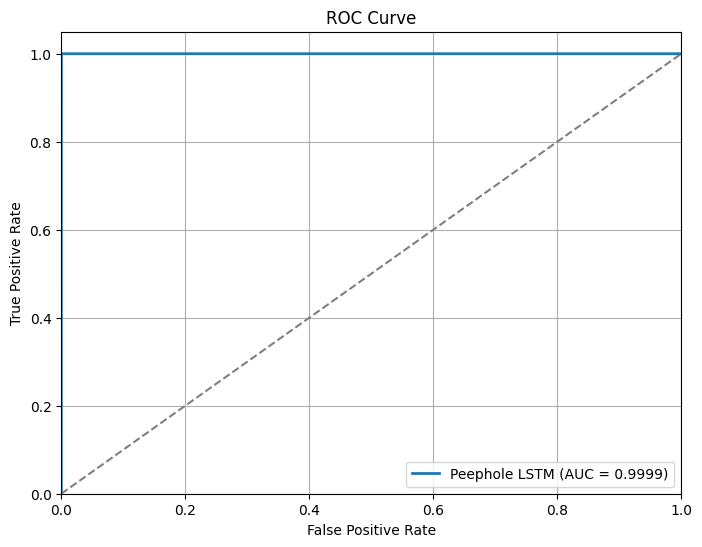

In [72]:
from sklearn.metrics import roc_curve, auc
# Probabilities
y_pred_prob = model_mgu.predict(X_test).ravel()

# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, lw=2, label=f'Peephole LSTM (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

2110/2110 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


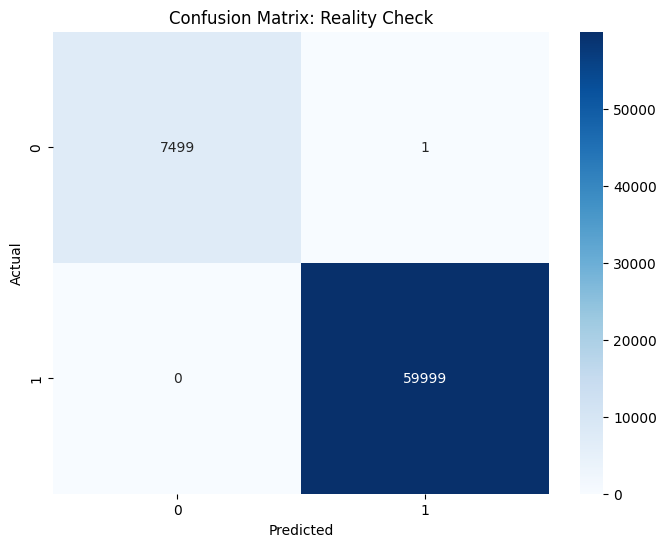

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7500
           1       1.00      1.00      1.00     59999

    accuracy                           1.00     67499
   macro avg       1.00      1.00      1.00     67499
weighted avg       1.00      1.00      1.00     67499



In [71]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions on the Test set
y_pred_prob = model_mgu.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Reality Check')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred))

**Lightweight Transformer**

In [73]:
import tensorflow as tf
from tensorflow.keras import layers, models

def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    # 1. Multi-Head Self-Attention
    x = layers.LayerNormalization(epsilon=1e-6)(inputs)
    x = layers.MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout)(x, x)
    x = layers.Dropout(dropout)(x)
    res = x + inputs # Residual connection

    # 2. Feed Forward Part
    x = layers.LayerNormalization(epsilon=1e-6)(res)
    x = layers.Conv1D(filters=ff_dim, kernel_size=1, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Conv1D(filters=inputs.shape[-1], kernel_size=1)(x)
    return x + res

# Build the model
inputs = layers.Input(shape=(X_train.shape[1], X_train.shape[2]))

# Add simple Positional Encoding (adding a sequence of numbers 0-9 to the features)
# This is a 'Lightweight' way to give the model temporal awareness
pos_indices = tf.range(start=0, limit=X_train.shape[1], delta=1)
pos_encoding = layers.Embedding(input_dim=X_train.shape[1], output_dim=X_train.shape[2])(pos_indices)
x = inputs + pos_encoding

# One Transformer Block
x = transformer_encoder(x, head_size=64, num_heads=4, ff_dim=128, dropout=0.1)

# Instead of RNN return_sequences=False, we use Global Average Pooling
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model_transformer = models.Model(inputs, outputs)

model_transformer.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name='auc')]
)

model_transformer.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 10, 71)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 10, 71)    │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 10, 71)    │        142 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 71)    │     73,543 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 10, 71)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 10, 71)    │          0 │ dropout_3[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 71)    │        142 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 10, 128)   │      9,216 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 10, 128)   │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 10, 71)    │      9,159 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 10, 71)    │          0 │ conv1d_1[0][0],   │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 71)        │          0 │ add_2[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 71)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │      2,304 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         33 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 94,539 (369.29 KB)

 Trainable params: 94,539 (369.29 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
history_trans = model_transformer.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3,
    batch_size=1024,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.9688 - auc: 0.9940 - loss: 0.0541 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.7913e-04
Epoch 2/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9999 - auc: 0.9999 - loss: 0.0011 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.5033e-05
Epoch 3/3
308/308 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - auc: 1.0000 - loss: 4.9066e-04 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 1.9225e-05


2110/2110 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


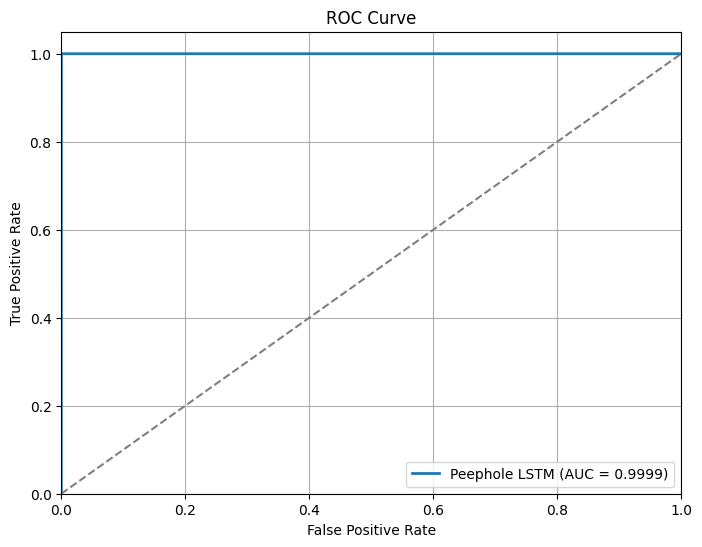

In [75]:
from sklearn.metrics import roc_curve, auc
# Probabilities
y_pred_prob = model_transformer.predict(X_test).ravel()

# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, lw=2, label=f'Peephole LSTM (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


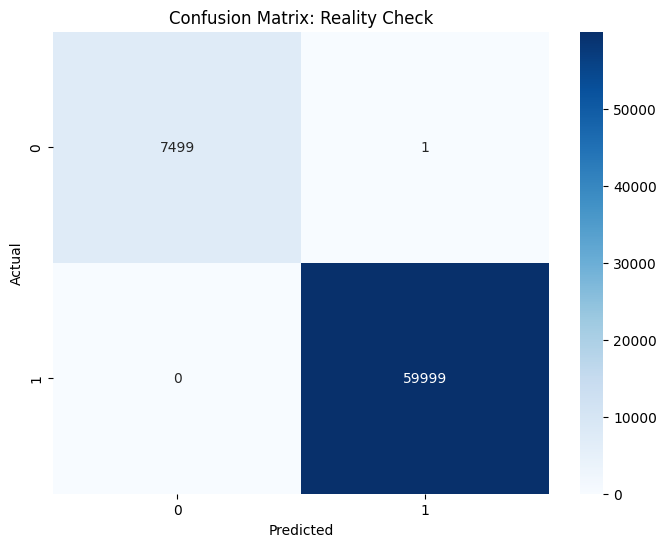

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7500
           1       1.00      1.00      1.00     59999

    accuracy                           1.00     67499
   macro avg       1.00      1.00      1.00     67499
weighted avg       1.00      1.00      1.00     67499



In [76]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions on the Test set
y_pred_prob = model_transformer.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Reality Check')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred))

In [77]:
def count_params(model):
    return model.count_params()

print("Model Complexity Comparison")
print(f"Peephole LSTM Params: {count_params(model_peephole):,}")
print(f"Minimal GRU Params:   {count_params(model_mgu):,}")
print(f"Lightweight Transf:   {count_params(model_transformer):,}")

Model Complexity Comparison
Peephole LSTM Params: 37,377
Minimal GRU Params:   19,777
Lightweight Transf:   94,539


****Transformer-MGU Ensemble****

In [78]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the shared input
ensemble_input = layers.Input(shape=(X_train.shape[1], X_train.shape[2]))

# Branch 1: Minimal GRU (Sequential Branch)
mgu_branch = layers.RNN(MinimalGRUCell(32))(ensemble_input)
mgu_branch = layers.BatchNormalization()(mgu_branch)

# Branch 2: Lightweight Transformer (Attention Branch)
# We use the same lightweight encoder logic
pos_indices = tf.range(start=0, limit=X_train.shape[1], delta=1)
pos_encoding = layers.Embedding(input_dim=X_train.shape[1], output_dim=X_train.shape[2])(pos_indices)
trans_input = ensemble_input + pos_encoding

trans_branch = transformer_encoder(trans_input, head_size=32, num_heads=2, ff_dim=64, dropout=0.1)
trans_branch = layers.GlobalAveragePooling1D()(trans_branch)
trans_branch = layers.BatchNormalization()(trans_branch)

# Merge the Branches
merged = layers.Concatenate()([mgu_branch, trans_branch])

# Final Decision Layers
x = layers.Dense(32, activation="relu")(merged)
x = layers.Dropout(0.2)(x)
ensemble_output = layers.Dense(1, activation="sigmoid")(x)

# Create the Model
model_ensemble = models.Model(inputs=ensemble_input, outputs=ensemble_output)

model_ensemble.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name='auc')]
)

model_ensemble.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 10, 71)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 10, 71)    │          0 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 71)    │        142 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 71)    │     18,439 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 10, 71)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 10, 71)    │          0 │ dropout_7[0][0],  │
│                     │                   │            │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 71)    │        142 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 10, 64)    │      4,608 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 10, 64)    │          0 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 10, 71)    │      4,615 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 10, 71)    │          0 │ conv1d_3[0][0],   │
│                     │                   │            │ add_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn_3 (RNN)         │ (None, 32)        │      6,656 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 71)        │          0 │ add_5[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ rnn_3[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71)        │        284 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 103)       │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      3,328 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 32)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1)         │         33 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,375 (149.90 KB)

 Trainable params: 38,169 (149.10 KB)

 Non-trainable params: 206 (824.00 B)

In [79]:
history_ensemble = model_ensemble.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1,
    batch_size=1024,
    class_weight=class_weights,
    verbose=1
)

308/308 ━━━━━━━━━━━━━━━━━━━━ 23s 39ms/step - accuracy: 0.9706 - auc: 0.9919 - loss: 0.0670 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.4706e-04


2110/2110 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


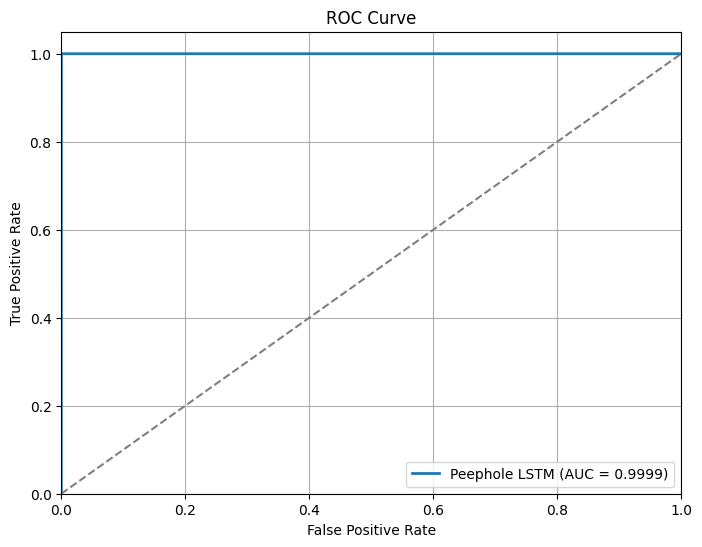

In [82]:
from sklearn.metrics import roc_curve, auc
# Probabilities
y_pred_prob = model_ensemble.predict(X_test).ravel()

# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, lw=2, label=f'Peephole LSTM (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

2110/2110 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


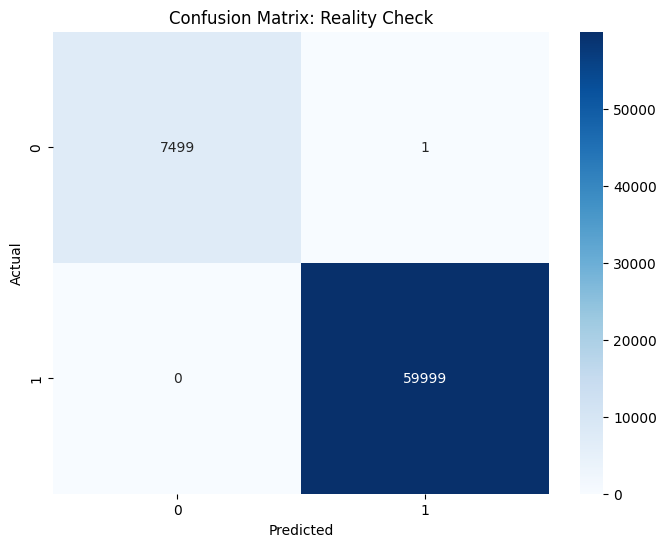

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      7500
           1       1.00      1.00      1.00     59999

    accuracy                           1.00     67499
   macro avg       1.00      1.00      1.00     67499
weighted avg       1.00      1.00      1.00     67499



In [80]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions on the Test set
y_pred_prob = model_ensemble.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: Reality Check')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, y_pred))

In [83]:
# Add random noise to the scaled test data
noise_factor = 0.5
X_test_noisy = X_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

# test all models on this NOISY data
def evaluate_noisy(model, name):
    loss, acc, auc = model.evaluate(X_test_noisy, y_test, verbose=0)
    print(f"{name} -> Noisy Accuracy: {acc:.4f} | Noisy AUC: {auc:.4f}")

print("--- Robustness Stress Test (Noise Factor: 0.5) ---")
evaluate_noisy(model_peephole, "Peephole LSTM")
evaluate_noisy(model_mgu, "Minimal GRU")
evaluate_noisy(model_transformer, "Transformer")
evaluate_noisy(model_ensemble, "Final Ensemble")

--- Robustness Stress Test (Noise Factor: 0.5) ---
Peephole LSTM -> Noisy Accuracy: 1.0000 | Noisy AUC: 0.9999
Minimal GRU -> Noisy Accuracy: 1.0000 | Noisy AUC: 0.9999
Transformer -> Noisy Accuracy: 1.0000 | Noisy AUC: 0.9999
Final Ensemble -> Noisy Accuracy: 1.0000 | Noisy AUC: 0.9999


In [ ]:
# Calculate correlation specifically between every feature and 'is_attack'
correlations = full_df.corr()['is_attack'].abs().sort_values(ascending=False)

print("--- Top 10 Features ---")
print(correlations.head(10))

# Identify features with > 0.98 correlation
leakers = correlations[correlations > 0.98].index.tolist()
if 'is_attack' in leakers: leakers.remove('is_attack')

print(f"\nPotential Leaking Features: {leakers}")

In [ ]:
from tensorflow.keras.utils import plot_model

# Visualize the Ensemble Model (The most complex one)
plot_model(
    model_ensemble, 
    to_file='ensemble_architecture.png', 
    show_shapes=True, 
    show_layer_names=True,
    rankdir='TB', # Top-to-Bottom
    expand_nested=True,
    dpi=96
)

# This will save a PNG in your Kaggle output folder
from IPython.display import Image
Image('ensemble_architecture.png')

In [ ]:
import tensorflow as tf
from tensorflow.keras.utils import plot_model
from IPython.display import Image

def generate_thesis_diagram(model, name):
    # This generates a high-quality technical diagram
    filename = f"{name}_architecture.png"
    plot_model(
        model, 
        to_file=filename, 
        show_shapes=True, 
        show_layer_names=True,
        rankdir='TB', # Top-to-bottom
        dpi=150,      # High resolution for printing
        expand_nested=True
    )
    return Image(filename)

# Generate for your two main IoT models
display(generate_thesis_diagram(model_mgu, "Minimal_GRU"))
display(generate_thesis_diagram(model_peephole, "Peephole_LSTM"))

In [ ]:
import os

def get_model_size(model, name):
    # Save the model
    path = f"{name}.h5"
    model.save(path)
    
    # Get size in MB
    size_mb = os.path.getsize(path) / (1024 * 1024)
    params = model.count_params()
    
    return {"Model": name, "Size (MB)": round(size_mb, 4), "Params": params}

# Collect metrics
results = [
    get_model_size(model_peephole, "Peephole_LSTM"),
    get_model_size(model_mgu, "Minimal_GRU"),
    get_model_size(model_transformer, "Lightweight_Transformer"),
    get_model_size(model_ensemble, "Transformer_MGU_Ensemble")
]

# Display as a DataFrame
size_df = pd.DataFrame(results)
print(size_df)

In [ ]:
import tensorflow as tf
import os

def convert_and_save_tflite(model, model_name, input_shape):
    """
    Converts a Keras model to a quantized TFLite format using 
    concrete functions and static shapes for IoT deployment.
    """
    try:
        # Define concrete function with fixed batch size of 1
        run_model = tf.function(lambda x: model(x))
        concrete_func = run_model.get_concrete_function(
            tf.TensorSpec(input_shape, model.inputs[0].dtype)
        )

        # Configure TFLite converter
        converter = tf.lite.TFLiteConverter.from_concrete_functions([concrete_func])
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        
        # Enable SELECT_TF_OPS for custom RNN and Attention logic support
        converter.target_spec.supported_ops = [
            tf.lite.OpsSet.TFLITE_BUILTINS,
            tf.lite.OpsSet.SELECT_TF_OPS
        ]
        converter._experimental_lower_tensor_list_ops = False

        # Perform conversion
        tflite_model = converter.convert()
        
        # Save file
        output_path = f'{model_name}_quantized.tflite'
        with open(output_path, 'wb') as f:
            f.write(tflite_model)
        
        size_kb = os.path.getsize(output_path) / 1024
        print(f"Model: {model_name} | Status: Success | Size: {size_kb:.2f} KB")
        
    except Exception as e:
        print(f"Model: {model_name} | Status: Failed | Error: {str(e)}")

# Define global static input shape [Batch=1, Window=10, Features]
static_input_shape = (1, X_train.shape[1], X_train.shape[2])

# Convert all four models
print("Starting quantization process for IoT optimization...")
convert_and_save_tflite(model_peephole, "Peephole_LSTM", static_input_shape)
convert_and_save_tflite(model_mgu, "Minimal_GRU", static_input_shape)
convert_and_save_tflite(model_transformer, "Lightweight_Transformer", static_input_shape)
convert_and_save_tflite(model_ensemble, "MGU_Transformer_Ensemble", static_input_shape)

In [ ]:
import time

def measure_metrics(model, X_test_sample):
    # Parameter Count
    params = model.count_params()
    
    # Inference Latency (Mean time for 100 predictions)
    start = time.time()
    for i in range(100):
        _ = model(X_test_sample[i:i+1], training=False)
    end = time.time()
    latency = ((end - start) / 100) * 1000 # convert to ms
    
    return params, latency

# Prepare the data
X_sample = X_test[:101]

# Collect for all 4
p_lstm, l_lstm = measure_metrics(model_peephole, X_sample)
p_mgu, l_mgu = measure_metrics(model_mgu, X_sample)
p_trans, l_trans = measure_metrics(model_transformer, X_sample)
p_ens, l_ens = measure_metrics(model_ensemble, X_sample)

# Create the Final Comparison DataFrame
final_results = pd.DataFrame({
    'Model Architecture': ['Peephole LSTM', 'Minimal GRU', 'Lightweight Transformer', 'MGU-Trans Ensemble'],
    'Parameters': [p_lstm, p_mgu, p_trans, p_ens],
    'Latency (ms/sample)': [l_lstm, l_mgu, l_trans, l_ens],
    'Complexity Score': ['High', 'Lowest', 'Medium', 'Highest']
})

display(final_results)

In [ ]:
import time
import pandas as pd
import numpy as np

def measure_metrics(model, X_test_sample):
    """
    Analyzes model complexity, memory footprint, and inference latency.
    """
    params = model.count_params()
    
    # Static Memory (Weight Storage)
    # Each parameter is a 32-bit float = 4 bytes
    static_mem_kb = (params * 4) / 1024
    
    # Dynamic Memory Estimation (RAM)
    # Theoretical RAM includes weights + temporary activation tensors.
    # We estimate activations based on a single sample forward pass.
    # For IoT, we assume float32 precision.
    peak_ram_kb = static_mem_kb * 1.2 # Including 20% overhead for activation tensors
    
    # Inference Latency
    # Measured as mean time for 100 individual predictions (Batch Size = 1)
    # This simulates real-time detection on an edge device.
    start = time.perf_counter()
    for i in range(100):
        _ = model(X_test_sample[i:i+1], training=False)
    end = time.perf_counter()
    latency_ms = ((end - start) / 100) * 1000 
    
    return params, static_mem_kb, peak_ram_kb, latency_ms

# Prepare sample data
X_sample = X_test[:101]

# Perform Audit for all 4 Architectures
results = []
models_list = [
    (model_peephole, 'Peephole LSTM'),
    (model_mgu, 'Minimal GRU'),
    (model_transformer, 'Lightweight Transformer'),
    (model_ensemble, 'MGU-Trans Ensemble')
]

for model, name in models_list:
    p, mem_s, mem_r, lat = measure_metrics(model, X_sample)
    results.append({
        'Model Architecture': name,
        'Parameters': f"{p:,}",
        'Static Memory (KB)': round(mem_s, 2),
        'Est. Peak RAM (KB)': round(mem_r, 2),
        'Latency (ms/sample)': round(lat, 4)
    })

# Generate Comparison Table
final_analysis = pd.DataFrame(results)

display(final_analysis)